**Data Availability**

The original datasets are not included in this repository because they are provided by the educational platform and are subject to distribution restrictions.

The notebook contains the complete analysis workflow and all outputs.

# Проект. Исследование стартапов

## Цель и задачи

**Цель**

Провести исследовательский анализ рынка венчурного финансирования стартапов на основе исторических данных, чтобы определить перспективные направления для инвестирования и выявить закономерности между характеристиками компаний (отрасль, стадия, сроки финансирования, объём и тип инвестиций, количество раундов, география) и их инвестиционной эффективностью.

Проанализировать взаимосвязи между типами финансирования, объёмами инвестиций, динамикой раундов и уровнем возврата средств, поскольку инвестор планирует оценить целесообразность выхода на рынок с покупкой и развитием компаний и определить оптимальную стратегию на 2015 год.

**Задачи**
1. Загрузить данные и ознакомиться с их структурой и содержанием.
 
 
2. Провести предобработку данных:

  - удалить дубликаты;

  - обработать пропуски;

  - проверить корректность числовых и временных показателей;

  - выявить и исключить аномальные значения;

  - при необходимости ограничить период исследования.

3. Провести исследовательский анализ данных:

  - изучить структуру рынка стартапов по отраслям и регионам;

  - проанализировать распределение компаний по стадиям и срокам финансирования;

  - исследовать объёмы и популярность различных типов инвестиций;

  - классифицировать рыночные сегменты на массовые, средние и нишевые;

  - проанализировать динамику раундов и объёмов финансирования по годам;

  - изучить взаимосвязь между объёмами инвестиций, количеством раундов и статусом компаний;

  - рассчитать долю возврата средств по типам финансирования и оценить её устойчивость во времени.


4. Сформулировать выводы и подготовить рекомендации по инвестиционной стратегии с ориентацией на 2015 год.

## Шаг 1. Знакомство с данными: загрузка и предобработка

Датасет получен из базы данных стартапов.

Название основного датасета — `cb_investments.zip`. Внутри архива один файл — `cb_investments.csv`.

Описание данных:
* `name` — название компании.
* `homepage_url` — ссылка на сайт компании.
* `category_list` — категории, в которых работает компания. Указываются через `|`.
* `market` — основной рынок или отрасль компании.
* `funding_total_usd` — общий объём привлечённых инвестиций в долларах США.
* `status` — текущий статус компании, например `operating`, `closed` и так далее.
* `country_code` — код страны, например USA.
* `state_code` — код штата или региона, например, CA.
* `region` — регион, например, SF Bay Area.
* `city` — город, в котором расположена компания.
* `funding_rounds` — общее число раундов финансирования.
* `participants` — число участников в раундах финансирования.
* `founded_at` — дата основания компании.
* `founded_month` — месяц основания в формате `YYYY-MM`.
* `founded_quarter` — квартал основания в формате `YYYY-QN`.
* `founded_year` — год основания.
* `first_funding_at` — дата первого финансирования.
* `mid_funding_at` — дата среднего по времени раунда финансирования.
* `last_funding_at` — дата последнего финансирования.
* `seed` — сумма инвестиций на посевной стадии.
* `venture` — сумма венчурных инвестиций.
* `equity_crowdfunding` — сумма, привлечённая через долевой краудфандинг.
* `undisclosed` — сумма финансирования нераскрытого типа.
* `convertible_note` — сумма инвестиций через конвертируемые займы.
* `debt_financing` — сумма долгового финансирования.
* `angel` — сумма инвестиций от бизнес-ангелов.
* `grant` — сумма полученных грантов.
* `private_equity` — сумма инвестиций в виде прямых (частных) вложений.
* `post_ipo_equity` — сумма финансирования после IPO.
* `post_ipo_debt` — сумма долгового финансирования после IPO.
* `secondary_market` — сумма сделок на вторичном рынке.
* `product_crowdfunding` — сумма, привлечённая через продуктовый краудфандинг.
* `round_A` — `round_H` — сумма инвестиций в соответствующем раунде.

Название дополнительного датасета — `cb_returns.csv`. Он содержит суммы возвратов по типам финансирования в миллионах долларов по годам.

Описание данных:
* `year` — год возврата средств.
* `seed` — сумма возвратов от посевных инвестиций.
* `venture` — сумма возвратов от венчурных инвестиций.
* `equity_crowdfunding` — сумма, возвращённая по долевому краудфандингу.
* `undisclosed` — сумма возвратов нераскрытого типа.
* `convertible_note` — сумма возвратов через конвертируемые займы.
* `debt_financing` — сумма возвратов от долгового финансирования.
* `angel` — сумма возвратов бизнес-ангелам.
* `grant` — сумма возвратов по грантам.
* `private_equity` — сумма возвратов прямых (частных) вложений.
* `post_ipo_equity` — сумма возвратов от IPO.
* `post_ipo_debt` — сумма возвратов от долгового IPO.
* `secondary_market` — сумма возвратов от сделок на вторичном рынке.
* `product_crowdfunding` — сумма возвратов по продуктовому краудфандингу.



## Содержимое проекта

1. [Загрузка данных и знакомство с ними](#chapter1)
2. [Предобработка данных](#chapter2)
    * 2.1. [Проверка названий столбцов датафрейма](#chapter2.1)
    * 2.2. [Преобразование типов данных, индексация и удаление полностью пустых строк](#chapter2.2)
    * 2.3. [Обработка текстовых признаков, заполнение пропусков и проверка на дубликаты](#chapter2.3)
    * 2.4. [Промежуточный вывод и полнота данных](#chapter2.4)
3. [Инжиниринг признаков](#chapter3)
    * 3.1. [Группы по срокам финансирования](#chapter3.1)
    * 3.2. [Выделение средних и нишевых сегментов рынка](#chapter3.2)
4. [Работа с выбросами и анализ](#chapter4)
    * 4.1. [Анализируем и помечаем выбросы в каждом из сегментов](#chapter4.1)
    * 4.2. [Определяем границы рассматриваемого периода, отбрасываем аномалии](#chapter4.2)
    * 4.3. [Анализ типов финансирования по объёму и популярности](#chapter4.3)
5. [Анализ динамики](#chapter5)
    * 5.1. [Динамика предоставления финансирования по годам](#chapter5.1)
    * 5.2. [Динамика размера общего финансирования по массовым сегментам рынка для растущих в 2014 году сегментов](#chapter5.2)
    * 5.3. [Годовая динамика доли возвращённых средств по типам финансирования](#chapter5.3)
6. [Итоговый вывод и рекомендации](#chapter6)

In [1]:
# Импортируем библиотеки
import pandas as pd

# Загружаем библиотеки для визуализации данных
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.patches import Patch
import matplotlib.colors as mcolors


<a id='chapter1'></a>
## 1. Загрузка данных и знакомство с ними

In [2]:
# Выгружаем датасеты
investments = pd.read_csv("datasets/cb_investments.zip", sep=';', low_memory=False)
returns = pd.read_csv("datasets/cb_returns.csv")

Познакомимся с данными датасета `cb_investments.zip` — выведем первые строки методом head(), а информацию о датафрейме методом `info()`:

In [3]:
# Снимаем ограничение на количество отображаемых столбцов
pd.set_option('display.max_columns', None)

# Выводим первые 10 строк датафрейма
investments.head(10)

,name,homepage_url,category_list,market,funding_total_usd,status,country_code,state_code,region,city,funding_rounds,participants,founded_at,founded_month,founded_quarter,founded_year,first_funding_at,mid_funding_at,last_funding_at,seed,venture,equity_crowdfunding,undisclosed,convertible_note,debt_financing,angel,grant,private_equity,post_ipo_equity,post_ipo_debt,secondary_market,product_crowdfunding,round_A,round_B,round_C,round_D,round_E,round_F,round_G,round_H
0,Harvard University,http://harvard.edu,|Education|,Education,"9,00,00,000",operating,USA,MA,Boston,Cambridge,1.0,NaN,1636-09-08,NaN,NaN,1636.0,2014-01-06,NaN,2014-01-06,0.0,0.0,0.0,0.0,0.0,0.0,0.0,90000000.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,University of New Brunswick,http://www.unb.ca,NaN,NaN,"20,00,000",operating,NaN,NaN,NaN,NaN,1.0,NaN,1785-01-01,NaN,NaN,1785.0,2014-05-15,NaN,2014-05-15,0.0,2000000.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,DuPont,http://www.dupont.com,|Business Services|Agriculture|Automotive|Inve...,Business Services,"90,00,000",operating,USA,DE,"Wilmington, Delaware",Wilmington,1.0,1.0,1802-07-19,NaN,NaN,1802.0,2009-07-02,2009-07-02,2009-07-02,0.0,9000000.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,University of Michigan,http://www.umich.edu/,|Education|,Education,"77,00,000",operating,USA,MI,Detroit,Ann Arbor,3.0,0.0,1817-01-01,NaN,NaN,1817.0,2013-11-21,2013-11-21,2014-11-03,0.0,0.0,0.0,1600000.0,0.0,0.0,0.0,6100000.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,Case Western Reserve University,http://www.case.edu,|Education|,Education,"5,40,000",operating,USA,OH,Cleveland,Cleveland,1.0,NaN,1826-01-01,NaN,NaN,1826.0,2014-01-14,NaN,2014-01-14,0.0,0.0,0.0,0.0,0.0,0.0,0.0,540000.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
5,Xavier University,http://www.xavier.edu/,NaN,NaN,"1,90,00,000",operating,USA,OH,Cincinnati,Cincinnati,1.0,NaN,1831-01-01,NaN,NaN,1831.0,2014-10-23,NaN,2014-10-23,0.0,0.0,0.0,0.0,0.0,0.0,0.0,19000000.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
6,Tulane University,http://tulane.edu/,|Education|,Education,"1,20,00,000",operating,USA,LA,New Orleans,New Orleans,4.0,0.0,1834-01-01,NaN,NaN,1834.0,2013-09-05,2013-09-05,2013-12-22,0.0,0.0,0.0,0.0,0.0,0.0,0.0,12000000.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
7,Duke University,http://www.duke.edu,|Education|,Education,"87,00,000",operating,USA,NC,Raleigh,Durham,1.0,NaN,1838-01-01,NaN,NaN,1838.0,2014-01-12,NaN,2014-01-12,0.0,8700000.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
8,"Virginia Commonwealth University, Richmond",http://www.vcu.edu/,NaN,NaN,"60,00,000",operating,USA,VA,Richmond,Richmond,1.0,NaN,1838-01-01,NaN,NaN,1838.0,2014-09-30,NaN,2014-09-30,0.0,0.0,0.0,0.0,0.0,0.0,0.0,6000000.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
9,WeGame,http://www.WeGame.com,|Social Media|,Social Media,"35,00,000",acquired,USA,CA,SF Bay Area,San Francisco,2.0,2.0,1840-01-01,NaN,NaN,1840.0,2007-10-01,2007-10-01,2008-03-01,500000.0,3000000.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,3000000.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [4]:
# Выводим информацию о датафрейме
investments.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 54294 entries, 0 to 54293
Data columns (total 40 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   name                  49437 non-null  object 
 1   homepage_url          45989 non-null  object 
 2   category_list         45477 non-null  object 
 3    market               45477 non-null  object 
 4    funding_total_usd    49438 non-null  object 
 5   status                48124 non-null  object 
 6   country_code          44165 non-null  object 
 7   state_code            30161 non-null  object 
 8   region                44165 non-null  object 
 9   city                  43322 non-null  object 
 10  funding_rounds        49438 non-null  float64
 11  participants          30473 non-null  float64
 12  founded_at            38554 non-null  object 
 13  founded_month         38482 non-null  object 
 14  founded_quarter       38482 non-null  object 
 15  founded_year       

In [5]:
# Рассчитаем процента пропусков с сортировкой от большего к меньшему
(investments.isna().sum() / len(investments) * 100).sort_values(ascending=False).round(2)

state_code              44.45
mid_funding_at          44.21
participants            43.87
founded_month           29.12
founded_quarter         29.12
founded_at              28.99
founded_year            28.99
city                    20.21
country_code            18.66
region                  18.66
category_list           16.24
 market                 16.24
homepage_url            15.30
status                  11.36
name                     8.95
private_equity           8.94
round_E                  8.94
round_F                  8.94
round_D                  8.94
round_C                  8.94
round_G                  8.94
round_B                  8.94
round_A                  8.94
product_crowdfunding     8.94
secondary_market         8.94
post_ipo_debt            8.94
post_ipo_equity          8.94
venture                  8.94
grant                    8.94
angel                    8.94
debt_financing           8.94
convertible_note         8.94
undisclosed              8.94
equity_cro

Датасет `investments` содержит **40 столбцов и 54 294 строки** с информацией о компаниях и их финансировании (название, отрасль, регион, статус, объём инвестиций, типы финансирования, раунды и даты).

После первичного анализа данных можно сделать следующие выводы:

**Структура данных:**

Столбцы соответствуют описанию проекта: присутствуют характеристики компаний, показатели по раундам финансирования, детализация по типам инвестиций и временные параметры.

**Типы данных:**

- Большинство инвестиционных показателей имеют тип `float64` и загружены корректно.

- Столбец `funding_total_usd` имеет тип `object` и содержит значения с запятыми (например, 9,00,00,000), требуется очистка и приведение к числовому формату.

- Даты (`founded_at`, `first_funding_at`, `last_funding_at` и др.) имеют тип `object` и требуют преобразования в `datetime`.

- `founded_year` хранится как `float64`, целесообразно привести к целочисленному типу.

- В названиях некоторых столбцов присутствуют лишние пробелы ( `market`, `funding_total_usd`), что требует исправления.

**Пропущенные значения**:

- Значительная доля пропусков обнаружена в `state_code` (**44%**), `participants` (**44%**), `mid_funding_at` (**44%**), а также в датах основания (около `29%`) и географических признаках (**18–20%**).

- Почти 9% строк имеют системные пропуски сразу во всех финансовых показателях.

**Особенности данных**:

- В выборке присутствуют не только классические стартапы, но и крупные организации (например, университеты), что может влиять на распределение объёмов финансирования.

- В столбцах типов финансирования много нулевых значений — требуется проверить, отражают ли они отсутствие привлечения данного типа средств или пропуск данных.

- Возможны выбросы в объёмах финансирования, что особенно важно при анализе венчурных инвестиций.

**Единообразие и подготовка:**

- Строковые признаки (`name`, `market`, `city`, `region`) следует проверить на единообразие написания.

- Необходимо проверить наличие дубликатов компаний.

- Требуется анализ логической согласованности дат и инвестиционных показателей.

В целом данные подходят для анализа венчурного рынка, однако требуют очистки форматов, преобразования типов данных и детальной работы с пропусками перед проведением исследовательского анализа.

Познакомимся с данными датасета `returns`:

In [6]:
# Выводим датафрейм
display(returns)

,year,seed,venture,equity_crowdfunding,undisclosed,convertible_note,debt_financing,angel,grant,private_equity,post_ipo_equity,post_ipo_debt,secondary_market,product_crowdfunding
0,2000,16.70,55.40,0.00,78.21,0.00,8.66,6.43,0.0,0.00,0.94,0.00,0.20,0.00
1,2001,2.88,23.49,0.00,21.50,0.01,4.49,1.18,0.0,0.00,0.46,0.00,0.46,0.00
2,2002,6.59,209.42,0.00,25.77,0.02,3.42,3.41,0.0,1.51,0.34,0.00,0.06,0.00
3,2003,7.74,233.86,0.00,9.40,0.01,1.09,3.41,0.0,1.62,2.11,0.00,0.08,0.00
4,2004,9.93,555.90,0.00,33.19,0.01,13.55,9.18,0.0,2.19,3.38,0.00,0.55,0.00
5,2005,26.60,2628.92,0.00,9.51,0.02,35.09,31.06,0.0,2.40,3.51,0.00,0.05,0.00
6,2006,61.81,3100.18,0.19,46.74,1.78,113.21,47.75,0.0,16.67,20.58,0.00,0.12,0.00
7,2007,70.41,3585.37,0.01,55.37,3.22,125.68,164.51,0.0,88.81,24.36,0.00,0.57,0.00
8,2008,89.72,2717.02,0.03,41.02,1.71,397.54,102.83,0.0,130.38,84.28,0.00,0.47,0.00
9,2009,160.21,2501.29,0.18,37.50,2.25,394.10,97.21,0.0,203.70,76.76,0.00,0.12,0.02


In [7]:
# Выводим информацию о датафрейме
returns.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15 entries, 0 to 14
Data columns (total 14 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   year                  15 non-null     int64  
 1   seed                  15 non-null     float64
 2   venture               15 non-null     float64
 3   equity_crowdfunding   15 non-null     float64
 4   undisclosed           15 non-null     float64
 5   convertible_note      15 non-null     float64
 6   debt_financing        15 non-null     float64
 7   angel                 15 non-null     float64
 8   grant                 15 non-null     float64
 9   private_equity        15 non-null     float64
 10  post_ipo_equity       15 non-null     float64
 11  post_ipo_debt         15 non-null     float64
 12  secondary_market      15 non-null     float64
 13  product_crowdfunding  15 non-null     float64
dtypes: float64(13), int64(1)
memory usage: 1.8 KB


Датасет `returns` содержит **14 столбцов и 15 строк** с агрегированной информацией о годовых объёмах возвратов средств по различным типам финансирования.

После первичного анализа можно сделать следующие выводы:

**Структура столбцов соответствует описанию в задании.**
В таблице присутствует год (`year`) и показатели возвратов по всем видам финансирования (`seed`, `venture`, `angel`, `debt_financing`, `private_equity`, `post_ipo_equity` и др.).

**Типы данных:**

- `year` — `int64`, что корректно для временного признака.

- Все финансовые показатели имеют тип `float64`, что соответствует денежным значениям с возможной дробной частью.
Преобразование типов данных не требуется.

**Пропущенные значения:**

Пропуски отсутствуют — во всех столбцах по 15 ненулевых значений. Это упрощает дальнейший анализ и исключает необходимость обработки `NaN`.

**Особенности данных:**

- Данные агрегированы по годам (одна строка — один год), что означает макроуровень анализа без детализации по компаниям.

- Значения представлены в миллионах долларов — важно учитывать это при сопоставлении с датасетом `investments`, где суммы указаны в долларах США.

- В ранние годы по отдельным инструментам наблюдаются нулевые значения (например, `equity_crowdfunding`), что может отражать отсутствие данного механизма финансирования в соответствующий период, а не пропуски данных.

В целом датасет корректен, полностью заполнен и готов к использованию для анализа динамики возвратов и расчёта показателей эффективности по типам финансирования.

<a id='chapter2'></a>
## 2. Предобработка данных
<a id='chapter2.1'></a>
### 2.1. Проверка названий столбцов датафрейма.

Мы заметили, что в названиях столбцов есть лишние пробелы (например, из-за ошибок ввода или особенностей формата файла). Это может помешать обращению к данным, уберем их.

In [8]:
# Удаляем лишние пробелы в начале и в конце названий всех столбцов
investments.columns = investments.columns.str.strip()

In [9]:
# Проверяем названия всех колонок в виде списка
investments.columns.tolist()

['name',
 'homepage_url',
 'category_list',
 'market',
 'funding_total_usd',
 'status',
 'country_code',
 'state_code',
 'region',
 'city',
 'funding_rounds',
 'participants',
 'founded_at',
 'founded_month',
 'founded_quarter',
 'founded_year',
 'first_funding_at',
 'mid_funding_at',
 'last_funding_at',
 'seed',
 'venture',
 'equity_crowdfunding',
 'undisclosed',
 'convertible_note',
 'debt_financing',
 'angel',
 'grant',
 'private_equity',
 'post_ipo_equity',
 'post_ipo_debt',
 'secondary_market',
 'product_crowdfunding',
 'round_A',
 'round_B',
 'round_C',
 'round_D',
 'round_E',
 'round_F',
 'round_G',
 'round_H']

Мы привели заголовки `investments` к единому стандарту. Столбцы в `returns` в дополнительной очистке не нуждаются.

<a id='chapter2.2'></a>
### 2.2. Преобразование типов данных, индексация и удаление полностью пустых строк.

В столбце `funding_total_usd` суммы записаны как текст с разделителями разрядов (запятыми). Чтобы использовать эти данные в расчетах, необходимо очистить их от лишних символов и привести к числовому типу `float`.

In [10]:
# 1. Удаляем запятые из строк
# 2. Преобразуем в числовой тип (float)
investments['funding_total_usd'] = pd.to_numeric(
    investments['funding_total_usd'].str.replace(',', ''), 
    errors='coerce'
)

In [11]:
# Выведем первые строки столбца
investments['funding_total_usd'].head()

0    90000000.0
1     2000000.0
2     9000000.0
3     7700000.0
4      540000.0
Name: funding_total_usd, dtype: float64

Для корректного анализа временных промежутков переведем столбцы с датами из типа `object` в формат `datetime`: 

In [12]:
# Список столбцов с датами
date_columns = ['founded_at', 'first_funding_at', 'mid_funding_at', 'last_funding_at']

# Приведение к формату datetime с указанием формата даты
for col in date_columns:
    investments[col] = pd.to_datetime(
        investments[col],
        format='%Y-%m-%d',
        errors='coerce'
    )

# Проверяем типы данных
investments[date_columns].dtypes

founded_at          datetime64[ns]
first_funding_at    datetime64[ns]
mid_funding_at      datetime64[ns]
last_funding_at     datetime64[ns]
dtype: object

Столбцы `founded_month` и `founded_quarter` содержат информацию о периодах. Преобразуем их в специальные типы данных `period[M]` (месяц) и` period[Q]` (квартал). Это позволит корректно сортировать их и группировать данные по времени, не привязываясь к конкретному дню.

In [13]:
# Преобразуем месяц в период (YYYY-MM)
investments['founded_month'] = pd.to_datetime(investments['founded_month'], errors='coerce').dt.to_period('M')

# Преобразуем квартал в период (YYYY-QN)
investments['founded_quarter'] = pd.to_datetime(investments['founded_quarter'], errors='coerce').dt.to_period('Q')

Для корректного отображения столбца `founded_year` и экономии памяти приведем его к целочисленному типу `int64`, который поддерживает наличие пропущенных значений.

In [14]:
# Приводим год основания к целочисленному типу с поддержкой пропусков
investments['founded_year'] = investments['founded_year'].astype('Int64')

Проверяем типы данных, которые хранят значения даты и времени:

In [15]:
investments[['founded_at', 'first_funding_at', 'mid_funding_at',
             'last_funding_at', 'founded_month', 'founded_quarter', 'founded_year']].dtypes



founded_at          datetime64[ns]
first_funding_at    datetime64[ns]
mid_funding_at      datetime64[ns]
last_funding_at     datetime64[ns]
founded_month            period[M]
founded_quarter      period[Q-DEC]
founded_year                 Int64
dtype: object

Установим столбец `year` в качестве индекса датафрейма `returns`. Поскольку данные представляют собой временной ряд (одна строка на один год), использование года в качестве индекса упростит поиск, фильтрацию и визуализацию динамики возвратов.


In [16]:
# Устанавливаем столбец year как индекс и сохраняем изменения в датафрейме
returns = returns.set_index('year')

# Проверяем обновленную структуру таблицы
returns.head()

,seed,venture,equity_crowdfunding,undisclosed,convertible_note,debt_financing,angel,grant,private_equity,post_ipo_equity,post_ipo_debt,secondary_market,product_crowdfunding
year,,,,,,,,,,,,,
2000,16.70,55.40,0.0,78.21,0.00,8.66,6.43,0.0,0.00,0.94,0.0,0.20,0.0
2001,2.88,23.49,0.0,21.50,0.01,4.49,1.18,0.0,0.00,0.46,0.0,0.46,0.0
2002,6.59,209.42,0.0,25.77,0.02,3.42,3.41,0.0,1.51,0.34,0.0,0.06,0.0
2003,7.74,233.86,0.0,9.40,0.01,1.09,3.41,0.0,1.62,2.11,0.0,0.08,0.0
2004,9.93,555.90,0.0,33.19,0.01,13.55,9.18,0.0,2.19,3.38,0.0,0.55,0.0


Удалим из датафрейма строки, которые полностью состоят из пропусков (NaN). Такие строки часто появляются при чтении файлов из-за пустых областей в конце таблицы или ошибок экспорта. Они не несут полезной нагрузки и могут исказить итоговую статистику и подсчет количества записей.


In [17]:
# Сохраняем исходное количество строк
initial_rows = investments.shape[0]

# Удаляем полностью пустые строки и создаем независимую копию
investments = investments.dropna(how='all').copy()

# Считаем разницу и процент отброшенных данных
deleted_rows = initial_rows - investments.shape[0]
percent_deleted = (deleted_rows / initial_rows) * 100

print(f"Строк до очистки: {initial_rows}")
print(f"Удалено пустых строк: {deleted_rows} ({percent_deleted:.2f}%)")
print(f"Осталось строк: {investments.shape[0]}")

Строк до очистки: 54294
Удалено пустых строк: 4856 (8.94%)
Осталось строк: 49438


<a id='chapter2.3'></a>
### 2.3. Обработка текстовых признаков, заполнение пропусков и проверка на дубликаты

#### Обработка текстовых признаков и заполнение пропусков.

Для дальнейшей очистки и заполнения пропусков выделим все столбцы с текстовыми данными (тип `object`) и применим операции приведения к регистру и заполнения «заглушками» только к строковым признакам, не затрагивая числа и даты.

In [18]:
# Выбираем названия всех столбцов, содержащих текстовые данные (тип object)
text_cols = investments.select_dtypes(include='object').columns

# Выводим список найденных текстовых столбцов
text_cols

Index(['name', 'homepage_url', 'category_list', 'market', 'status',
       'country_code', 'state_code', 'region', 'city'],
      dtype='object')

In [19]:
# Создадим словарь с «заглушками»
fill_values = {
    'name': 'unknown_company',
    'homepage_url': 'no_website',
    'category_list': 'unknown_category',
    'market': 'unknown_market',
    'status': 'unknown_status',
    'country_code': 'unknown_country',
    'state_code': 'unknown_state',
    'region': 'unknown_region',
    'city': 'unknown_city'
}
# Заполняем пропуски в каждом столбце из словаря
for col, value in fill_values.items():
    investments[col] = investments[col].fillna(value)

Для обеспечения единообразия данных приведем строковые значения в основных категориальных столбцах к нижнему регистру. Это позволит избежать дублирования одних и тех же названий из-за разницы в написании и обеспечит корректную группировку данных при дальнейшем анализе.

In [20]:
# Список строковых столбцов для проверки
cols_to_check = [
    'name', 'homepage_url', 'category_list', 'market', 'status',
    'country_code', 'state_code', 'region', 'city'
]

# Проверяем наличие лишних пробелов в начале и конце строк
def check_spaces(df, columns):
    """
    Функция проверяет наличие лишних пробелов 
    в начале и конце строк в указанных столбцах DataFrame.
    
    df — DataFrame для проверки
    columns — список столбцов для анализа
    """
    for col in columns:
        leading_trailing_spaces = (df[col] != df[col].str.strip()).sum()
        print(f"{col}: строк с лишними пробелами — {leading_trailing_spaces}")

check_spaces(investments, cols_to_check)        

# Проверяем, остались ли значения с разным регистром
for col in cols_to_check:
    unique_original = investments[col].nunique()
    unique_lower = investments[col].str.lower().nunique()
    print(f"{col}: уникальных значений до lower() — {unique_original}, после lower() — {unique_lower}")

name: строк с лишними пробелами — 0
homepage_url: строк с лишними пробелами — 0
category_list: строк с лишними пробелами — 0
market: строк с лишними пробелами — 44251
status: строк с лишними пробелами — 0
country_code: строк с лишними пробелами — 0
state_code: строк с лишними пробелами — 0
region: строк с лишними пробелами — 1
city: строк с лишними пробелами — 0
name: уникальных значений до lower() — 49351, после lower() — 49332
homepage_url: уникальных значений до lower() — 45851, после lower() — 45847
category_list: уникальных значений до lower() — 16676, после lower() — 16676
market: уникальных значений до lower() — 940, после lower() — 940
status: уникальных значений до lower() — 4, после lower() — 4
country_code: уникальных значений до lower() — 116, после lower() — 116
state_code: уникальных значений до lower() — 62, после lower() — 62
region: уникальных значений до lower() — 1090, после lower() — 1090
city: уникальных значений до lower() — 4189, после lower() — 4189


Проверка выявила наличие различий в регистре и лишних пробелов в строковых признаках.
Для устранения дублирования значений и корректной сегментации приведём все строки к единому формату: удалим пробелы по краям и применим нижний регистр.

In [21]:
# Список строковых столбцов
cols_to_clean = [
    'name', 'homepage_url', 'category_list', 'market', 'status',
    'country_code', 'state_code', 'region', 'city'
]

# Удаляем пробелы и приводим к нижнему регистру
for col in cols_to_clean:
    investments[col] = investments[col].str.strip().str.lower()

In [22]:
# Проверяем, остались ли пробелы
check_spaces(investments, cols_to_check)

name: строк с лишними пробелами — 0
homepage_url: строк с лишними пробелами — 0
category_list: строк с лишними пробелами — 0
market: строк с лишними пробелами — 0
status: строк с лишними пробелами — 0
country_code: строк с лишними пробелами — 0
state_code: строк с лишними пробелами — 0
region: строк с лишними пробелами — 0
city: строк с лишними пробелами — 0


In [23]:
# Выведем первые строки
investments.head(10)

,name,homepage_url,category_list,market,funding_total_usd,status,country_code,state_code,region,city,funding_rounds,participants,founded_at,founded_month,founded_quarter,founded_year,first_funding_at,mid_funding_at,last_funding_at,seed,venture,equity_crowdfunding,undisclosed,convertible_note,debt_financing,angel,grant,private_equity,post_ipo_equity,post_ipo_debt,secondary_market,product_crowdfunding,round_A,round_B,round_C,round_D,round_E,round_F,round_G,round_H
0,harvard university,http://harvard.edu,|education|,education,90000000.0,operating,usa,ma,boston,cambridge,1.0,NaN,NaT,NaT,NaT,1636,2014-01-06,NaT,2014-01-06,0.0,0.0,0.0,0.0,0.0,0.0,0.0,90000000.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,university of new brunswick,http://www.unb.ca,unknown_category,unknown_market,2000000.0,operating,unknown_country,unknown_state,unknown_region,unknown_city,1.0,NaN,1785-01-01,NaT,NaT,1785,2014-05-15,NaT,2014-05-15,0.0,2000000.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,dupont,http://www.dupont.com,|business services|agriculture|automotive|inve...,business services,9000000.0,operating,usa,de,"wilmington, delaware",wilmington,1.0,1.0,1802-07-19,NaT,NaT,1802,2009-07-02,2009-07-02,2009-07-02,0.0,9000000.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,university of michigan,http://www.umich.edu/,|education|,education,7700000.0,operating,usa,mi,detroit,ann arbor,3.0,0.0,1817-01-01,NaT,NaT,1817,2013-11-21,2013-11-21,2014-11-03,0.0,0.0,0.0,1600000.0,0.0,0.0,0.0,6100000.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,case western reserve university,http://www.case.edu,|education|,education,540000.0,operating,usa,oh,cleveland,cleveland,1.0,NaN,1826-01-01,NaT,NaT,1826,2014-01-14,NaT,2014-01-14,0.0,0.0,0.0,0.0,0.0,0.0,0.0,540000.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
5,xavier university,http://www.xavier.edu/,unknown_category,unknown_market,19000000.0,operating,usa,oh,cincinnati,cincinnati,1.0,NaN,1831-01-01,NaT,NaT,1831,2014-10-23,NaT,2014-10-23,0.0,0.0,0.0,0.0,0.0,0.0,0.0,19000000.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
6,tulane university,http://tulane.edu/,|education|,education,12000000.0,operating,usa,la,new orleans,new orleans,4.0,0.0,1834-01-01,NaT,NaT,1834,2013-09-05,2013-09-05,2013-12-22,0.0,0.0,0.0,0.0,0.0,0.0,0.0,12000000.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
7,duke university,http://www.duke.edu,|education|,education,8700000.0,operating,usa,nc,raleigh,durham,1.0,NaN,1838-01-01,NaT,NaT,1838,2014-01-12,NaT,2014-01-12,0.0,8700000.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
8,"virginia commonwealth university, richmond",http://www.vcu.edu/,unknown_category,unknown_market,6000000.0,operating,usa,va,richmond,richmond,1.0,NaN,1838-01-01,NaT,NaT,1838,2014-09-30,NaT,2014-09-30,0.0,0.0,0.0,0.0,0.0,0.0,0.0,6000000.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
9,wegame,http://www.wegame.com,|social media|,social media,3500000.0,acquired,usa,ca,sf bay area,san francisco,2.0,2.0,1840-01-01,NaT,NaT,1840,2007-10-01,2007-10-01,2008-03-01,500000.0,3000000.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,3000000.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


Категории разделены через |. Уберем крайние разделители:

In [24]:
investments['category_list'] = investments['category_list'].str.strip('|')

Очистка прошла успешно. Посмотрим кол-во уникальных значений:

#### Поиск и удаление дубликатов.
Посмотрим полные дубликаты строк, чтобы исключить технические повторы.

In [25]:
# Проверяем количество полных дубликатов
investments.duplicated().sum()

0

Полные дубликаты отсутствуют. Посмотрим кол-во уникальных значений строковых столбцов:

In [26]:
for col in cols_to_check:
    unique_original = investments[col].nunique()
    unique_lower = investments[col].str.lower().nunique()
    print(f"{col}: после очистки — {unique_original} уникальных значений")

name: после очистки — 49332 уникальных значений
homepage_url: после очистки — 45847 уникальных значений
category_list: после очистки — 16676 уникальных значений
market: после очистки — 440 уникальных значений
status: после очистки — 4 уникальных значений
country_code: после очистки — 116 уникальных значений
state_code: после очистки — 62 уникальных значений
region: после очистки — 1090 уникальных значений
city: после очистки — 4189 уникальных значений


Следующим шагом проверим полностью идентичные строки, включая финансовые показатели и раунды инвестиций, и удалим их, чтобы гарантировать уникальность каждой записи по всем ключевым колонкам.

In [27]:
# Указываем колонки для проверки точного дублирования
cols_to_check = [
    'name', 'homepage_url', 'city', 'country_code',
    'funding_total_usd', 'seed', 'venture', 'equity_crowdfunding', 'undisclosed',
    'convertible_note', 'debt_financing', 'angel', 'grant', 'private_equity',
    'post_ipo_equity', 'post_ipo_debt', 'secondary_market', 'product_crowdfunding',
    'round_A','round_B','round_C','round_D','round_E','round_F','round_G','round_H'
]

# Считаем количество полных дубликатов
full_duplicates_count = investments.duplicated(subset=cols_to_check).sum()
print(f"Количество полностью идентичных строк, которые будут удалены: {full_duplicates_count}")

# Удаляем полные дубликаты
investments_cleaned = investments.drop_duplicates(subset=cols_to_check)
print(f"Размер датафрейма после удаления полных дубликатов: {investments_cleaned.shape}")

Количество полностью идентичных строк, которые будут удалены: 4
Размер датафрейма после удаления полных дубликатов: (49434, 40)


Посмотрим пропуски в `funding_total_usd`. Строки без данных о финансировании не могут участвовать в анализе
объёма инвестиций и сроков финансирования, поэтому они исключаются из выборки.

In [28]:
# считаем количество пропусков
na_count = investments['funding_total_usd'].isna().sum()

# считаем долю пропусков в процентах
na_percent = na_count / len(investments) * 100

print(f'Количество пропусков: {na_count}')
print(f'Доля пропусков: {na_percent:.2f}%')

Количество пропусков: 8531
Доля пропусков: 17.26%


Доля в 17.26% ощутима, но не критична для датасета такого размера (около 50к строк). Так как `funding_total_usd` — ключевая переменная для анализа объёма инвестиций, заполнять её искусственно некорректно. Несмотря на наличие разбивки по типам раундов, нельзя гарантировать, что их сумма отражает полный объём финансирования. 

In [29]:
# сохраняем исходное количество строк
initial_count = len(investments)

# удаляем строки с NaN и нулевой суммой
investments = investments.dropna(subset=['funding_total_usd'])
investments = investments[investments['funding_total_usd'] > 0]

# считаем итоговое количество
final_count = len(investments)
removed_count = initial_count - final_count

print(f"Было строк: {initial_count}")
print(f"Стало строк: {final_count}")
print(f"Удалено всего: {removed_count} ({removed_count / initial_count:.2%})")

Было строк: 49438
Стало строк: 40907
Удалено всего: 8531 (17.26%)


**Восстановим пропущенные даты промежуточного финансирования `mid_funding_at`**. 

Сначала проверим логические ошибки в датах.
Затем заполним пропуски в столбце `mid_funding_at`. В качестве расчетного значения возьмем середину временного интервала между первым (`first_funding_at`) и последним (`last_funding_at`) раундами. Это позволит сохранить логику временной шкалы для каждой компании. В завершение оценим количество записей, которые не удалось восстановить (например, из-за отсутствия данных о других раундах).

In [30]:
(investments['last_funding_at'] < investments['first_funding_at']).sum()

0

In [31]:
# Определяем маску для строк, где mid_funding_at пропущен
is_na_mid = investments['mid_funding_at'].isna()

# Вычисляем середину интервала и заполняем пропуски
investments.loc[is_na_mid, 'mid_funding_at'] = (
    investments.loc[is_na_mid, 'first_funding_at'] + 
    (investments.loc[is_na_mid, 'last_funding_at'] - investments.loc[is_na_mid, 'first_funding_at']) / 2
)

# Оцениваем количество оставшихся пропусков
remaining_na = investments['mid_funding_at'].isna().sum()
print(f"Количество пропусков в 'mid_funding_at' после обработки: {remaining_na}")


Количество пропусков в 'mid_funding_at' после обработки: 1


In [32]:
# Выведем строку с пропуском
investments[investments['mid_funding_at'].isna()]

,name,homepage_url,category_list,market,funding_total_usd,status,country_code,state_code,region,city,funding_rounds,participants,founded_at,founded_month,founded_quarter,founded_year,first_funding_at,mid_funding_at,last_funding_at,seed,venture,equity_crowdfunding,undisclosed,convertible_note,debt_financing,angel,grant,private_equity,post_ipo_equity,post_ipo_debt,secondary_market,product_crowdfunding,round_A,round_B,round_C,round_D,round_E,round_F,round_G,round_H
33041,nubank,https://www.nubank.com.br/,consumer internet|financial services,financial services,16300000.0,operating,bra,unknown_state,sao paulo,são paulo,2.0,NaN,2013-01-01,2013-01,2013Q1,2013,NaT,NaT,2014-09-25,2000000.0,14300000.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,14300000.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


В записи с отсутствует дата первого раунда, что делает невозможным расчет «середины» по формуле. Поэтому единственный оставшийся пропуск в `mid_funding_at` заполним значением из `last_funding_at`, что позволяет сохранить в датасете информацию о крупном игроке (Nubank) без ущерба для полноты данных.

In [33]:
# Заполняем оставшийся пропуск
investments['mid_funding_at'] = investments['mid_funding_at'].fillna(investments['last_funding_at'])

# Выведем результат для конкретной строки с индексом 33041
investments.loc[[33041], ['first_funding_at', 'mid_funding_at', 'last_funding_at']]


,first_funding_at,mid_funding_at,last_funding_at
33041,NaT,2014-09-25,2014-09-25


In [34]:
# Рассчитаем процента пропусков с сортировкой от большего к меньшему
(investments.isna().sum() / len(investments) * 100).sort_values(ascending=False).round(2)

participants            33.19
founded_quarter         21.44
founded_month           21.44
founded_at              21.28
founded_year            21.28
first_funding_at         0.00
angel                    0.00
grant                    0.00
private_equity           0.00
post_ipo_equity          0.00
post_ipo_debt            0.00
name                     0.00
convertible_note         0.00
secondary_market         0.00
product_crowdfunding     0.00
round_A                  0.00
round_B                  0.00
round_C                  0.00
round_D                  0.00
round_E                  0.00
round_F                  0.00
round_G                  0.00
debt_financing           0.00
venture                  0.00
undisclosed              0.00
equity_crowdfunding      0.00
homepage_url             0.00
seed                     0.00
last_funding_at          0.00
mid_funding_at           0.00
funding_rounds           0.00
city                     0.00
region                   0.00
state_code

**Обработка оставшихся пропусков**

Столбец `participants` содержит около 33% пропусков.
Заполнение этих значений может привести к искажению данных, поэтому пропуски оставим без изменений.

Столбцы `founded_at` (21.28%), `founded_year` (21.28%)
и `founded_month` (21.44%) также содержат пропуски. Данные показатели отражают дату основания компании,
однако в рамках текущего проекта возраст компании не анализируется.

Заполнять год основания годом первого раунда финансирования некорректно, поскольку компания могла существовать задолго до привлечения инвестиций.

<a id='chapter2.4'></a>
### 2.4. Промежуточный вывод и полнота данных.

1. Проверка и стандартизация названий столбцов

- В названиях столбцов `investments` были обнаружены лишние пробелы, которые удалены.

- Заголовки приведены к единому стандарту: все строчные, без лишних пробелов.

- Датасет `returns` в дополнительной очистке не нуждается.

Названия столбцов единообразны, что исключает ошибки при обращении к данным.

2. Преобразование типов данных и индексация

- `funding_total_usd`: очищен от запятых и приведён к числовому типу `float64`.

- Временные признаки (`founded_at`, `first_funding_at`, `mid_funding_at`, `last_funding_at`) переведены в формат `datetime`.

- Периодические признаки (`founded_month`, `founded_quarter`) приведены к типам `period[M]` и `period[Q]`.

- Год основания (`founded_year`) приведён к типу `int64`, позволяющему хранить пропуски.

- В датасете `returns` столбец `year` установлен как индекс для удобства анализа временного ряда.

Типы данных корректны для анализа динамики, агрегирования по годам и расчетов показателей.

3. Очистка от полностью пустых строк

- До очистки: 54 294 строки

- Удалено пустых строк: 4 856 (≈8.94%)

- После очистки: 49 438 строк

Удаление коснулось только технических или пустых записей и не повлияло на качество анализа.

4. Обработка текстовых признаков

- Столбцы с текстом (`name`, `homepage_url`, `category_list`, `market`, `status`, `country_code`, `state_code`, `region`, `city`) заполнены заглушками для пропусков.

- Все строковые значения приведены к нижнему регистру для единообразия.

- В столбце `category_list` удалены крайние символы-разделители |.

Категориальные и текстовые признаки стандартизированы для корректного группирования и анализа.

5. Проверка на дубликаты

- Полные дубликаты отсутствуют.
- Полностью идентичные строки, включая финансовые показатели и раунды инвестиций (4 строки) были удалены.
- Пропуски в ключевой переменной `funding_total_usd`: 8 531 строка (17.26%), которые были удалены.

Ключевые показатели финансирования полностью актуальны, удаление строк с `NaN` корректно и не искажает анализ.

6. Временные показатели финансирования

- Пропуски в `mid_funding_at` восстановлены как середина интервала между `first_funding_at` и `last_funding_at`.

- Для одной строки без `first_funding_at` заполнено значением `last_funding_at`.

- Пропуски в датах основания (`founded_at`, `founded_month`, `founded_quarter`, `founded_year`) остаются, но они не критичны для анализа текущего проекта.

Временные признаки, необходимые для анализа динамики и сроков финансирования, полностью восстановлены.

**Итоговой вывод**

Данные достаточно полные для решения задач проекта:

- анализ структуры и динамики финансирования;

- сегментация компаний по рынкам;

- оценка распределения типов инвестиций;

- агрегирование по годам и расчёт долей возвратов.

Удаление пустых строк и строк без ключевых показателей не повлияло на объём информации. Пропуски в дополнительных признаках не критичны и могут учитываться при анализе с оговорками.

<a id='chapter3'></a>
## 3. Инжиниринг признаков
<a id='chapter3.1'></a>
### 3.1. Группы по срокам финансирования

Разделим компании на три категории:

1. Единичное финансирование — если был только один раунд.
2. Срок финансирования до года — если между первым и последним раундом прошло ≤ 365 дней.
3. Срок финансирования более года — если прошло более 365 дней.

Это позволит сравнить поведение компаний с разной стратегией привлечения капитала.

In [35]:
# Функция для определения группы финансирования
def define_funding_group(row):
    
    # Если был только один раунд
    if row['funding_rounds'] == 1:
        return 'Единичное финансирование'
    
    # Если отсутствует дата первого раунда (2 строки в данных)
    if pd.isna(row['first_funding_at']):
        return 'Нет данных'
    
    # Рассчитываем длительность финансирования
    duration_days = (row['last_funding_at'] - row['first_funding_at']).days
    
    # Разделяем по длительности
    if duration_days <= 365:
        return 'Срок финансирования до года'
    else:
        return 'Срок финансирования более года'


# Перезаписываем столбец funding_group
investments['funding_group'] = investments.apply(define_funding_group, axis=1)

# Проверяем распределение
print("Распределение компаний по группам:")
print(investments['funding_group'].value_counts())

# Проверим пропуски
print("\nКоличество пропусков:", investments['funding_group'].isna().sum())

Распределение компаний по группам:
Единичное финансирование          24113
Срок финансирования более года    12291
Срок финансирования до года        4501
Нет данных                            2
Name: funding_group, dtype: int64

Количество пропусков: 0


Рассчитаем:
1. Долю компаний в каждой группе (в процентах).
2. Долю общего объёма инвестиций, приходящуюся на каждую группу.

Для корректного сравнения зададим фиксированный порядок категорий.

In [36]:
# Фиксируем порядок категорий (без "Нет данных")
group_order = [
    'Единичное финансирование',
    'Срок финансирования до года',
    'Срок финансирования более года'
]

# Оставляем только основные 3 категории
filtered_data = investments[investments['funding_group'].isin(group_order)]


# Расчёт процента компаний
company_percent = (
    filtered_data['funding_group']
    .value_counts(normalize=True)
    .reindex(group_order) * 100
)

# Расчёт процента инвестиций
investment_sum = (
    filtered_data
    .groupby('funding_group')['funding_total_usd']
    .sum()
    .reindex(group_order)
)

investment_percent = (investment_sum / investment_sum.sum()) * 100


print("Процент компаний:")
print(company_percent)

print("\nПроцент инвестиций:")
print(investment_percent)

Процент компаний:
Единичное финансирование          58.948784
Срок финансирования до года       11.003545
Срок финансирования более года    30.047671
Name: funding_group, dtype: float64

Процент инвестиций:
funding_group
Единичное финансирование          30.619851
Срок финансирования до года        7.510528
Срок финансирования более года    61.869622
Name: funding_total_usd, dtype: float64


На основе рассчитанных данных мы видим заметную разницу между количеством компаний в каждой группе и реальным объемом привлеченного ими капитала.

**Распределение компаний и инвестиций:**
- Единичное финансирование: 58.9% компаний / 30.6% инвестиций.
- Срок до года: 11.0% компаний / 7.5% инвестиций.
- Срок более года: 30.0% компаний / 61.9% инвестиций.

Визуализируем эти показатели для наглядного сравнения структуры рынка. Первый график демонстрирует количественное распределение компаний по группам, а второй — долю капитала, которую аккумулирует каждая категория.

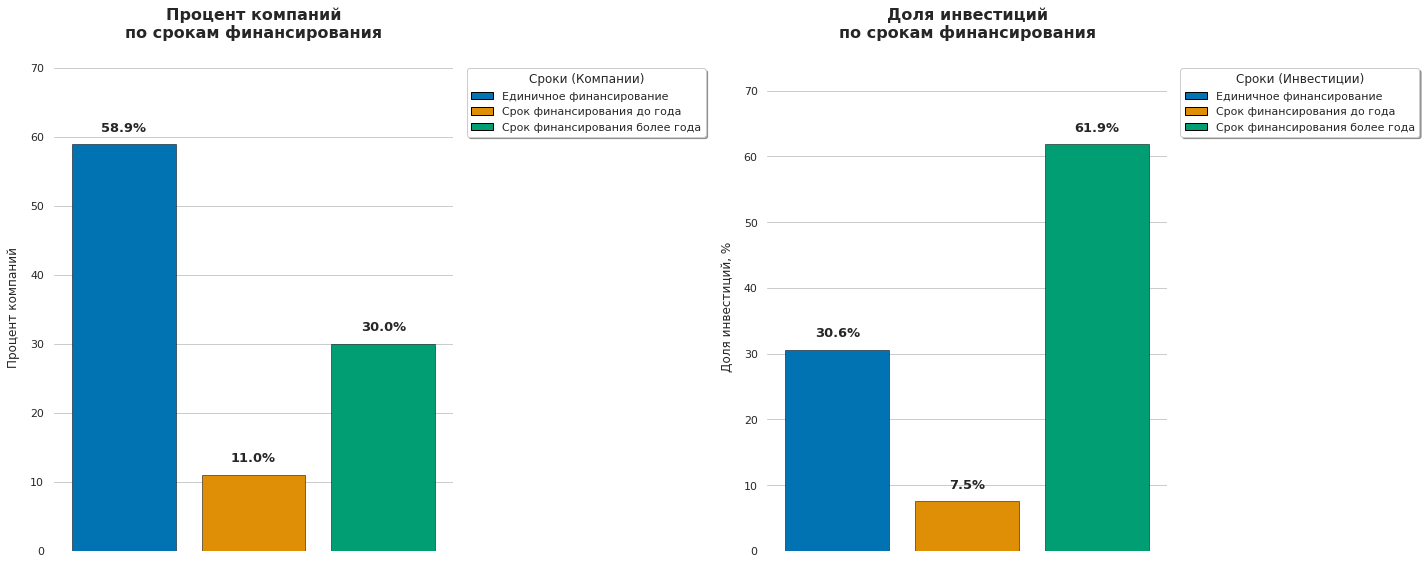

In [37]:
# Настройка общего стиля
sns.set_theme(style="whitegrid")
plt.rcParams.update({'font.size': 12})

# Создаем одну фигуру с двумя подграфиками (1 строка, 2 колонки)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(20, 8))

def draw_bar_chart(ax, data, title, ylabel, legend_title):
    palette = sns.color_palette("colorblind", len(data))
    
    # Строим столбцы
    bars = ax.bar(
        data.index,
        data.values,
        color=palette,
        edgecolor='black',
        linewidth=0.5
    )

    # Подписи процентов
    for bar in bars:
        height = bar.get_height()
        ax.annotate(f'{height:.1f}%',
                    xy=(bar.get_x() + bar.get_width() / 2, height),
                    xytext=(0, 10),
                    textcoords="offset points",
                    ha='center', va='bottom',
                    fontsize=13,
                    fontweight='bold')

    # Легенда
    legend_elements = [
        Patch(facecolor=palette[i], edgecolor='black', label=label) 
        for i, label in enumerate(data.index)
    ]
    ax.legend(
        handles=legend_elements, 
        title=legend_title, 
        bbox_to_anchor=(1.02, 1), 
        loc='upper left',
        frameon=True,
        shadow=True
    )

    # Оформление
    ax.set_title(title, fontsize=16, pad=25, fontweight='bold')
    ax.set_ylabel(ylabel, fontsize=12, labelpad=10)
    ax.set_xticks([]) # Убираем подписи снизу
    ax.set_ylim(0, max(data.values) * 1.2)
    sns.despine(ax=ax, left=True, bottom=True)

# Рисуем первый график (Компании)
draw_bar_chart(
    ax1, 
    company_percent, 
    'Процент компаний\nпо срокам финансирования', 
    'Процент компаний', 
    "Сроки (Компании)"
)

# Рисуем второй график (Инвестиции)
draw_bar_chart(
    ax2, 
    investment_percent, 
    'Доля инвестиций\nпо срокам финансирования', 
    'Доля инвестиций, %', 
    "Сроки (Инвестиции)"
)

plt.tight_layout()
plt.show()

Сопоставление количества компаний и реальных объемов привлеченного капитала выявило ключевую асимметрию рынка:

1. Доминирование единичных раундов

**Большинство** участников рынка (**58.9%**) ограничиваются **единичным финансированием**. Это указывает на то, что основная масса компаний находится либо на ранней стадии, либо не имеет стратегии многоэтапного привлечения средств. При этом, составляя более половины всех компаний, они аккумулируют лишь **30.6% от общего объема инвестиций**.

2. Эффективность долгосрочных стратегий

Компании с циклом финансирования **более года** представляют собой наиболее инвестиционно емкий сегмент. Занимая всего **30%** рынка по количеству, они аккумулируют подавляющую **долю капитала — 61.9%**. Это подтверждает, что долгосрочная стратегия привлечения средств характерна для наиболее масштабных и устойчивых проектов.

3. Специфика быстрорастущих проектов

**Наименьшая группа** — компании, привлекающие несколько раундов в течение одного года (**11%**). Несмотря на высокую активность, их **доля в общем капитале** минимальна — всего **7.5%**. Такая модель характерна для динамичных стартапов на этапе агрессивного тестирования гипотез, которые пока не вышли на крупные объемы вложений.

**Итоговое резюме**

«Почти две трети всех денег (62%) забирают всего 30% компаний, которые играют «в долгую». В то же время большинство стартапов (59%) ограничиваются лишь одним небольшим раундом. 

Это свидетельствует о том, что долгосрочная стратегия привлечения капитала характерна для более масштабных и инвестиционно ёмких проектов. Продолжительность финансирования напрямую связана с концентрацией инвестиционных ресурсов

<a id='chapter3.2'></a>
### 3.2. Выделение средних и нишевых сегментов рынка

Для венчурной компании важно понимать структуру рынка:

- где сосредоточено большинство стартапов,
- насколько рынок фрагментирован,
- есть ли концентрация в отдельных направлениях.

Это необходимо для оценки инвестиционной стратегии: массовые сегменты обеспечивают большой поток сделок, а нишевые — могут давать уникальные, но более рискованные возможности.

Сначала определим, как часто встречается каждый сегмент рынка.

In [38]:
# Подсчитываем количество компаний в каждом сегменте
market_counts = investments['market'].value_counts()

# Количество уникальных сегментов
print("Количество уникальных сегментов:", market_counts.shape[0])

# Просматриваем наиболее крупные сегменты
market_counts.head()

Количество уникальных сегментов: 395


software          4812
biotechnology     3590
unknown_market    2503
mobile            2344
e-commerce        1866
Name: market, dtype: int64

Разделим сегменты на три категории:

- mass — более 120 компаний  
- mid — от 35 до 120 включительно  
- niche — менее 35 компаний  

Такая агрегация позволит упростить дальнейший анализ и сосредоточиться на стратегически значимых направлениях. Чтобы избежать избыточной детализации, мы сохраняем названия только для массовых сегментов, а остальные группируем с помощью заглушек: значения категорий со средней частотой заменяются на `mid`, а редкие — на `niche`.

In [39]:
# Функция для классификации
def classify_segment(count):
    if count > 120:
        return 'mass'
    elif 35 <= count <= 120:
        return 'mid'
    else:
        return 'niche'

# Создаем справочник классификации
segment_classes = market_counts.apply(classify_segment)
segment_map = segment_classes.to_dict()


# Оставляем имя, если это mass, иначе заменяем на заглушку (mid или niche)
investments['market'] = investments['market'].apply(
    lambda x: x if segment_map.get(x) == 'mass' else segment_map.get(x)
)

# Считаем количество сегментов в каждой категории для графиков
segment_category_counts = segment_classes.value_counts()

print("Количество сегментов по категориям:")
print(segment_category_counts)

Количество сегментов по категориям:
niche    289
mid       57
mass      49
Name: market, dtype: int64


Визуализируем распределение количества компаний по сегментам, чтобы увидеть структуру рынка и границы между нишевыми, средними и массовыми направлениями.

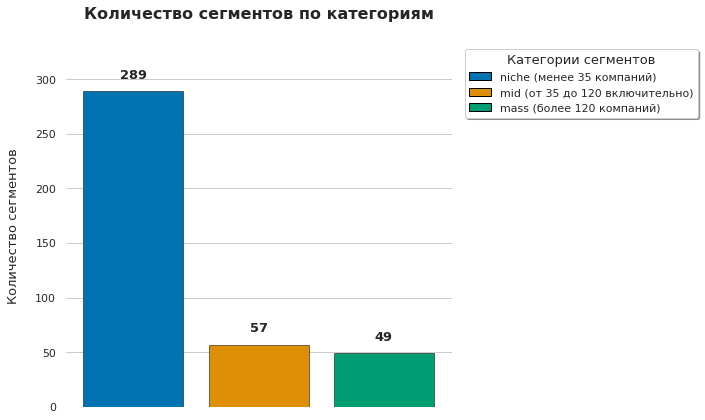

In [40]:
# Настройка общей эстетики графиков (белая сетка и размер шрифта)
sns.set_theme(style="whitegrid")
plt.rcParams.update({'font.size': 12})

# Словарь для расшифровки меток 
legend_desc = {
    'mass': 'mass (более 120 компаний)',
    'mid': 'mid (от 35 до 120 включительно)',
    'niche': 'niche (менее 35 компаний)'
}

# Создаем рабочую область (фигуру) и оси
fig, ax = plt.subplots(figsize=(10, 6))

# Генерируем цветовую палитру по количеству категорий
palette = sns.color_palette("colorblind", len(segment_category_counts))

# Отрисовка столбчатой диаграммы
bars = ax.bar(
    segment_category_counts.index,
    segment_category_counts.values,
    color=palette,
    edgecolor='black', # Тонкая черная рамка для четкости
    linewidth=0.5
)

# Добавление текстовых меток над столбцами (значения данных)
for bar in bars:
    height = bar.get_height()
    ax.annotate(f'{int(height)}',
                xy=(bar.get_x() + bar.get_width() / 2, height),
                xytext=(0, 10), # Смещение текста вверх на 10 пунктов
                textcoords="offset points",
                ha='center', va='bottom',
                fontsize=13,
                fontweight='bold')

# Формирование кастомной легенды с описанием сегментов
legend_elements = [
    Patch(facecolor=palette[i], 
          edgecolor='black', 
          label=legend_desc.get(label, label)) # Берем описание из словаря выше
    for i, label in enumerate(segment_category_counts.index)
]

# Настройка положения и стиля легенды (вынос за пределы графика)
ax.legend(
    handles=legend_elements, 
    title="Категории сегментов", 
    title_fontsize=13,
    fontsize=11,
    bbox_to_anchor=(1.02, 1), 
    loc='upper left',
    frameon=True,
    shadow=True
)

# Оформление осей и заголовка
ax.set_title('Количество сегментов по категориям', fontsize=16, pad=25, fontweight='bold')
ax.set_ylabel('Количество сегментов', fontsize=13, labelpad=15)
ax.set_xticks([]) # Скрываем текстовые метки под столбцами (они уже есть в легенде)
ax.set_ylim(0, max(segment_category_counts.values) * 1.15) # Запас сверху для подписей

# Удаляем лишние границы графика для современного вида
sns.despine(left=True, bottom=True)

plt.tight_layout()
plt.show()

Распределение сегментов демонстрирует классическую структуру с «длинным хвостом».

Подавляющее **большинство направлений (289 сегментов)** относятся к нишевым (`niche`). Это сегменты, в которых присутствует небольшое количество компаний. Такая структура говорит о высокой фрагментации рынка и наличии большого числа узкоспециализированных направлений.

**Средние сегменты (`mid`)** составляют **57 категорий**. Эти рынки уже имеют заметное количество игроков, но пока не достигли масштаба массовых индустрий.

**Массовые сегменты (`mass`)** представлены **49 категориями**. Несмотря на сравнительно небольшое количество таких сегментов, именно они обычно концентрируют наибольшее число компаний, инвестиций и конкурентной активности.

**Вывод**

Рынок стартапов характеризуется высокой фрагментацией:

- Большая часть индустрий представлена множеством узких ниш, где конкуренция относительно ниже.

- Массовые сегменты составляют лишь небольшую долю всех направлений, но именно они чаще всего становятся центрами инвестиционной активности.

- Для дальнейшего анализа индивидуальные сегменты внутри нишевых и средних категорий объединены в агрегированные группы `niche` и `mid`, тогда как массовые сегменты сохраняются отдельно.

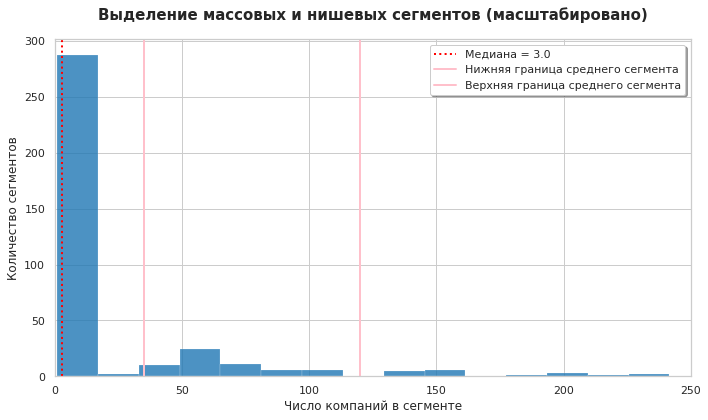

In [41]:
# Настройка стиля
sns.set_theme(style="whitegrid")
plt.rcParams.update({'font.size': 12})

fig, ax = plt.subplots(figsize=(10, 6))

# Строим гистограмму
sns.histplot(
    market_counts, 
    bins=300, # Увеличиваем число корзин для детализации
    color='tab:blue', 
    edgecolor='white',
    alpha=0.8,
    ax=ax
)

# Добавляем медиану
median_val = market_counts.median()
ax.axvline(median_val, color='red', linestyle=':', linewidth=2, label=f'Медиана = {median_val}')

# Границы сегментов
ax.axvline(35, color='pink', linestyle='-', linewidth=2, label='Нижняя граница среднего сегмента')
ax.axvline(120, color='pink', linestyle='-', linewidth=2, label='Верхняя граница среднего сегмента')


# Устанавливаем лимит чуть больше верхней границы, 
# чтобы рассмотреть нишевые и средние сегменты.
ax.set_xlim(0, 250) 
# ----------------------------------------------

# Оформление
ax.set_title('Выделение массовых и нишевых сегментов (масштабировано)', fontsize=15, fontweight='bold', pad=20)
ax.set_xlabel('Число компаний в сегменте', fontsize=12)
ax.set_ylabel('Количество сегментов', fontsize=12)

# Легенда
ax.legend(loc='upper right', frameon=True, shadow=True)

plt.tight_layout()
plt.show()


-   Гистограмма наглядно показывает, что основная масса данных «прижата» к левому краю. Пик в районе 0–15 компаний настолько велик, что остальные категории на его фоне выглядят как редкие выбросы.
-   **Микро-ниши как стандарт:** Медиана **3.0** (красный пунктир) делит рынок пополам — это значит, что в 50% всех существующих индустрий работает **не более 3 компаний**. Это подтверждает, что рынок стартапов состоит не из крупных отраслей, а из тысяч атомарных микро-рынков.
-   **«Разреженность» среднего сегмента:** В диапазоне от 35 до 120 компаний (зоны между розовыми линиями) наблюдается резкий спад частоты. Переход сегмента из «нишевого» в «средний» — это сложный порог, который преодолевает лишь малая часть направлений.


<a id='chapter4'></a>
## 4.  Работа с выбросами и анализ
<a id='chapter4.1'></a>
### 4.1. Анализируем и помечаем выбросы в каждом из сегментов

Заказчика интересует типичный размер инвестиций, предоставляемый одной компании. Для оценки будем использовать столбец `funding_total_usd`. Поскольку распределение венчурного финансирования, как правило,
сильно асимметрично и содержит выбросы используем `boxplot` (без отображения выбросов), чтобы увидеть диапазон типичных значений — внутри "усов".

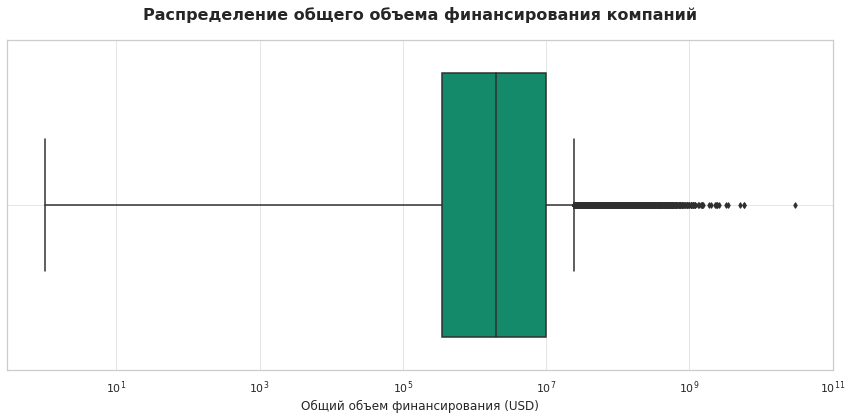

In [42]:
# Настройка стиля
sns.set_theme(style="whitegrid")
plt.figure(figsize=(12, 6))

color = "#009E73"  # основной цвет графика

# Построение боксплота
ax = sns.boxplot(
    x=investments['funding_total_usd'], 
    color=color,
    fliersize=4,
    linewidth=1.5
)

# Настройка осей и заголовков
ax.set_title('Распределение общего объема финансирования компаний', fontsize=16, fontweight='bold', pad=20)
ax.set_xlabel('Общий объем финансирования (USD)', fontsize=12)

# Логарифмическая шкала обязательна для таких данных
ax.set_xscale('log') 

# Добавляем сетку
plt.grid(True, which="both", ls="-", alpha=0.5)

plt.tight_layout()
plt.show()

На основе построенного боксплота можно сделать следующие выводы о размере финансирования компаний: 

- Типичный интервал (**основная масса**): Большинство компаний получают финансирование в диапазоне **от 400 тыс. до 10 млн. долларов** (это границы «ящика» — 25-й и 75-й процентили).
- Типичное среднее (**Медиана**): Центральное значение финансирования составляет примерно **2 млн. долларов**.
- **Граница аномалий**: Значения, превышающие примерно **25–30 млн. долларов**, визуально выходят за пределы «усов» и считаются аномально высокими (выбросами) для рынка в целом. На графике виден длинный «хвост» из компаний, получивших сотни миллионов и даже миллиарды долларов.

Определим выбросы внутри каждого сегмента отдельно. Благодаря тому, что мы уже сгруппировали мелкие рынки в `niche` и `mid`, массовые сегменты будут сравниваться сами с собой, а нишевые и средние — внутри своих групп.

In [43]:
# Функция для поиска выбросов через межквартильный размах (IQR)
def mark_outliers(group):
    q1 = group['funding_total_usd'].quantile(0.25)
    q3 = group['funding_total_usd'].quantile(0.75)
    iqr = q3 - q1
    
    # Нижняя граница (не ниже 0) и верхняя граница аномалий
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    
    # Возвращаем True для аномальных значений
    return (group['funding_total_usd'] < lower) | (group['funding_total_usd'] > upper)

# Применяем функцию к сгруппированным данным
investments['is_outlier'] = (
    investments
    .groupby('market', group_keys=False)
    .apply(mark_outliers)
)

# Формируем итоговую таблицу с анализом аномалий
outlier_analysis = investments.groupby('market')['is_outlier'].agg(['count', 'sum'])

# Переименовываем столбцы
outlier_analysis.columns = ['Всего компаний', 'Количество аномалий']

# Считаем долю аномальных компаний в процентах
outlier_analysis['Доля аномалий (%)'] = (
    (outlier_analysis['Количество аномалий'] / outlier_analysis['Всего компаний']) * 100
).round(2)

# Выводим ТОП-10 сегментов с самой высокой долей аномалий
top_outlier_segments = (
    outlier_analysis
    .sort_values(by='Доля аномалий (%)', ascending=False)
    .head(10)
)

print("Сегменты с наибольшей долей аномального финансирования:")
display(top_outlier_segments)


Сегменты с наибольшей долей аномального финансирования:


,Всего компаний,Количество аномалий,Доля аномалий (%)
market,,,
real estate,279,48,17.20
entertainment,150,25,16.67
consulting,349,58,16.62
search,291,48,16.49
cloud computing,152,25,16.45
photography,204,33,16.18
saas,272,44,16.18
technology,238,38,15.97
video,188,30,15.96


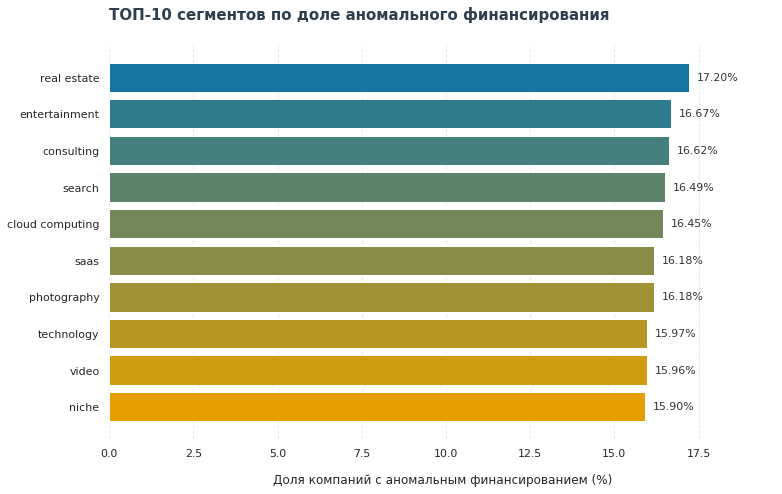

In [44]:
# Настройка стиля и шрифтов
sns.set_theme(style="whitegrid")
plt.rcParams.update({'font.size': 11})

# Подготовка данных: сортируем от меньшего к большему
data_plot = top_outlier_segments.sort_values(by='Доля аномалий (%)', ascending=True)

# Создание фигуры
fig, ax = plt.subplots(figsize=(11, 7))

# Создаем плавный градиент:
# #E69F00 — оранжево-желтый (mid)
# #0072B2 — насыщенный синий (niche)
colors = ["#E69F00", "#0072B2"] 
cmap = mcolors.LinearSegmentedColormap.from_list("my_palette", colors)
# Генерируем список цветов для наших столбцов
palette = [cmap(i/len(data_plot)) for i in range(len(data_plot))]

# Построение горизонтальных столбцов
bars = ax.barh(
    data_plot.index,
    data_plot['Доля аномалий (%)'],
    color=palette,
    edgecolor='white',
    linewidth=1
)

# 4. Добавляем подписи процентов
for bar in bars:
    width = bar.get_width()
    ax.annotate(f'{width:.2f}%', 
                xy=(width, bar.get_y() + bar.get_height() / 2),
                xytext=(8, 0), 
                textcoords="offset points",
                ha='left', va='center',
                fontsize=11,
                color='#333333', 
                fontweight='normal')

# Оформление заголовка и осей
ax.set_title('ТОП-10 сегментов по доле аномального финансирования', 
             fontsize=15, pad=25, fontweight='bold', color='#2c3e50', loc='left')

ax.set_xlabel('Доля компаний с аномальным финансированием (%)', fontsize=12, labelpad=15)

# Запас по оси X для текста
ax.set_xlim(0, max(data_plot['Доля аномалий (%)']) * 1.15)

# Тонкая настройка сетки и границ
ax.xaxis.grid(True, linestyle='--', alpha=0.4)
ax.yaxis.grid(False)
sns.despine(left=True, bottom=True)

plt.tight_layout()
plt.show()


На основе расчета IQR и визуализации ТОП-10 сегментов по доле выбросов:
- Сегменты **Real Estate (17.2%)** и **Entertainment (16.7%)** имеют самый высокий процент компаний со сверхвысоким финансированием. В этих отраслях разрыв между «обычным» стартапом и лидером наиболее критичен.

- Сегменты **Search**, **Cloud Computing** и **SaaS** показывают стабильно высокую долю аномалий (около **16.5%**). Это подтверждает стратегию инвесторов на максимальное масштабирование узкого круга фаворитов.
- Объединенная группа `niche` также вошла в ТОП-10 (**15.9%**). Даже в редких направлениях каждая шестая компания получает аномально высокие чеки.

**Итог**

Высокая доля аномалий (от 16% до 17%) во всех ведущих сегментах делает среднее арифметическое бесполезным для анализа. Для корректной оценки «типичного» чека в дальнейшем будем использовать медиану.

<a id='chapter4.2'></a>
### 4.2. Определяем границы рассматриваемого периода, отбрасываем аномалии

Для того чтобы результаты анализа были статистически значимыми и отражали реальные рыночные тренды, выполним проверку полноты данных: 

Прежде всего, проанализируем распределение инвестиционных раундов по месяцам в 2014 году, чтобы убедиться, что предоставленный массив данных за этот период является полным:

In [45]:
# Фильтруем данные за 2014 год и группируем по месяцам
data_2014 = investments[investments['mid_funding_at'].dt.year == 2014]
rounds_by_month = data_2014.groupby(data_2014['mid_funding_at'].dt.month).size()

print("Раунды по месяцам в 2014 году:")
print(rounds_by_month)

Раунды по месяцам в 2014 году:
mid_funding_at
1     739
2     600
3     676
4     645
5     600
6     740
7     687
8     559
9     548
10    497
11    306
12     23
dtype: int64


<a id='december_drop'></a>Анализ распределения инвестиционных раундов по месяцам **2014 года** показывает, что данные за этот год являются **неполными**. В течение первых месяцев фиксируется от 500 до 740 раундов, однако в **декабре** присутствует лишь **23 записи**, что существенно отличается от предыдущих месяцев и указывает на обрыв данных.

Это означает, что данные за конец года, вероятно, были загружены не полностью. Тем не менее 2014 год содержит значительное количество наблюдений за большинство месяцев, поэтому исключать его из анализа не будем.

В связи с этим 2014 год сохраняется в датасете, однако при интерпретации динамики необходимо учитывать возможную неполноту данных за конец года.

Приступаем к очистке аномалий (`is_outlier`), и ограничиваем выборку только «активными» годами, где количество зафиксированных раундов не менее 50.

In [46]:
# Исключаем компании с аномальным финансированием
investments_clean = investments[investments['is_outlier'] == False].copy()

# Считаем количество инвестиционных раундов по годам
rounds_per_year = investments_clean['mid_funding_at'].dt.year.value_counts()

# Определяем годы, где было 50 и более раундов
active_years = rounds_per_year[rounds_per_year >= 50].index

# Оставляем только записи из этих лет
investments_final = investments_clean[
    investments_clean['mid_funding_at'].dt.year.isin(active_years)
].copy()

# Удаляем служебный столбец
investments_final.drop(columns=['is_outlier'], inplace=True)

print(f"Активные годы: {sorted(list(active_years))}")
print(f"Итого строк после очистки: {len(investments_final)}")

Активные годы: [2000, 2003, 2004, 2005, 2006, 2007, 2008, 2009, 2010, 2011, 2012, 2013, 2014]
Итого строк после очистки: 35504


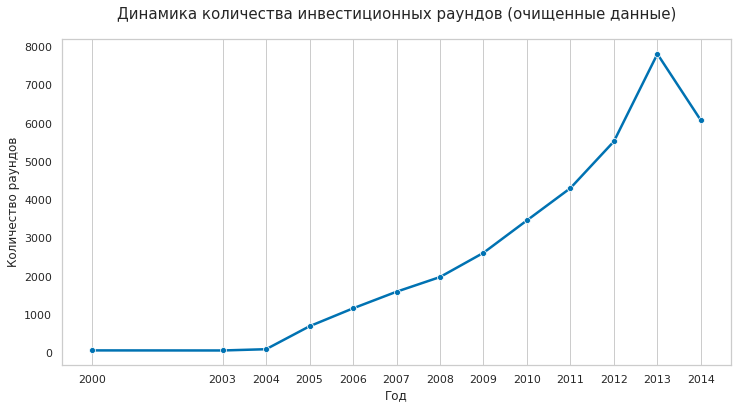

In [47]:
plt.figure(figsize=(12, 6))
# Считаем количество компаний по годам
yearly_trend = investments_final['mid_funding_at'].dt.year.value_counts().sort_index()

sns.lineplot(x=yearly_trend.index, y=yearly_trend.values, marker='o', color='#0072B2', linewidth=2.5)

plt.title('Динамика количества инвестиционных раундов (очищенные данные)', fontsize=15, pad=20)
plt.xlabel('Год', fontsize=12)
plt.ylabel('Количество раундов', fontsize=12)
plt.xticks(yearly_trend.index) # Чтобы показать каждый активный год
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()


Анализ полноты данных за 2014 год: 

- Проверка распределения раундов по месяцам выявила технический **«обрыв» данных в декабре 2014** года (всего 23 записи против ~700 в среднем по месяцам). Несмотря на это, 2014 год был сохранен в датасете, так как данные за первые 11 месяцев полны и критически важны для оценки актуальных трендов перед 2015 годом.
- **Очистка от аномалий**: Из исследования исключены компании, получившие аномальные объемы финансирования (выбросы, определенные методом IQR). Это позволило анализировать «реальный» рынок стартапов, не искаженный единичными сверхкрупными сделками.
- **Фильтрация по активности**: В итоговый датасет вошли только «активные» годы, в которых зафиксировано **не менее 50 инвестиционных раундов**. Это позволило сосредоточиться на периоде зрелого венчурного рынка (с 2000 года, за исключением этапа резкого спада активности в 2001–2002 годах).

Построенная визуализация наглядно подтверждает: 
- Начиная с 2004 года, наблюдается **устойчивая восходящая динамика**. Количество раундов выросло с нескольких сотен до пикового значения в ~7800 в 2013 году.
- Основной **рывок** произошел после **2010 года**, что указывает на массовое появление новых технологических проектов и доступность капитала.
- Видимое снижение количества раундов в 2014 году на графике не является признаком кризиса. Это следствие выявленной ранее неполноты данных за декабрь и естественной задержки обновления базы данных.



In [48]:
# Находим самую позднюю дату инвестиции в 2014 году
max_funding_2014 = investments[investments['last_funding_at'].dt.year == 2014]['last_funding_at'].max()

print(f"Самая поздняя дата инвестиционного раунда в 2014: {max_funding_2014}")

Самая поздняя дата инвестиционного раунда в 2014: 2014-12-31 00:00:00


<a id='chapter4.3'></a>
### 4.3.  Анализ типов финансирования по объёму и популярности

Сравним популярность различных раундов, общие объемы вложений и суммы фактически возвращенных средств по каждому направлению.

In [49]:
# Список целевых типов финансирования
funding_types = [
    'seed', 'venture', 'equity_crowdfunding', 'undisclosed', 'convertible_note', 
    'debt_financing', 'angel', 'grant', 'private_equity', 'post_ipo_equity', 
    'post_ipo_debt', 'secondary_market', 'product_crowdfunding'
]

# Суммарные объемы (в млн USD)
volumes = (investments_final[funding_types].sum() / 1_000_000).sort_values(ascending=False)

# Популярность (количество компаний)
popularity = (investments_final[funding_types] > 0).sum().sort_values(ascending=False)

#  Возвраты (на основе датасета returns, без 2014 года)
returns_total = returns.drop(index=2014, errors='ignore').sum().sort_values(ascending=False)


Двойной график наглядно покажет разрыв между «массовостью» и «весом» сделок. Мы увидим, где рынок берет количеством (много мелких вложений), а где — огромными суммами (редкие, но крупные чеки).
График возвратов покажет, какие типы инвестиций принесли инвесторам деньги за все время.

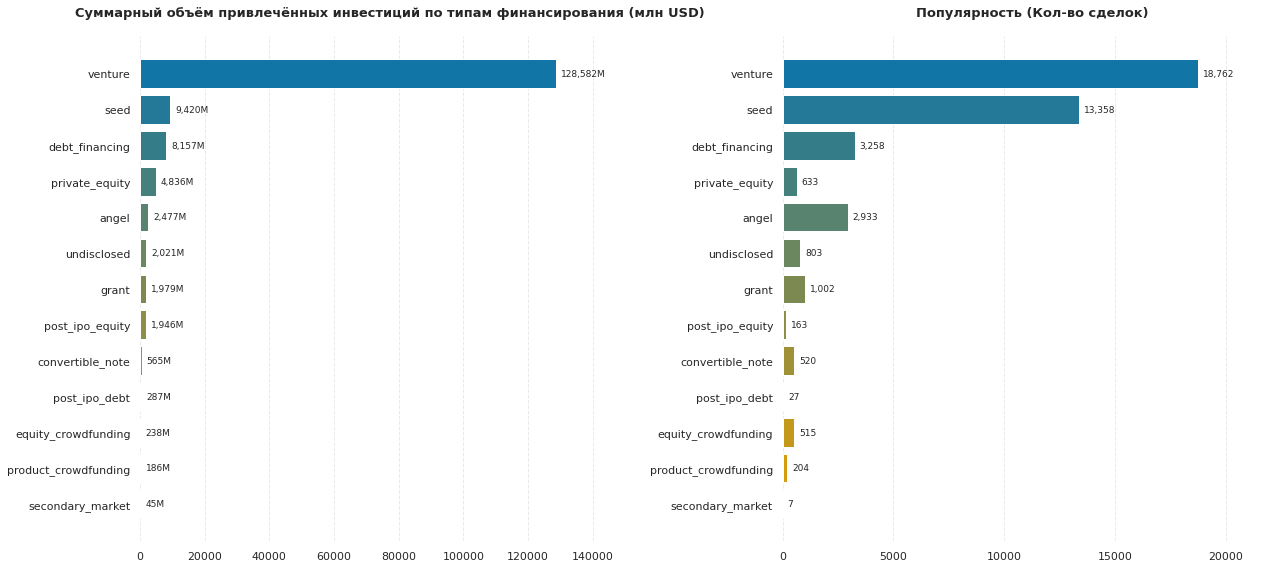

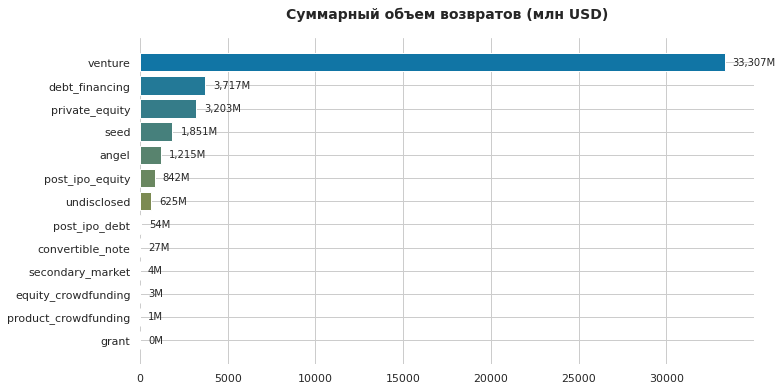

In [50]:
# 1. Настройка общего стиля и градиента
sns.set_theme(style="whitegrid")
plt.rcParams.update({'font.size': 10})
colors = ["#E69F00", "#0072B2"] 
cmap = mcolors.LinearSegmentedColormap.from_list("my_palette", colors)

# Создание фигуры с двумя графиками рядом
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(18, 8))

# Левый график: 
data_vol = volumes.sort_values(ascending=True)
palette_vol = [cmap(i/len(data_vol)) for i in range(len(data_vol))]

bars1 = ax1.barh(data_vol.index, data_vol.values, color=palette_vol, edgecolor='white')
for bar in bars1:
    width = bar.get_width()
    ax1.annotate(f'{width:,.0f}M', xy=(width, bar.get_y() + bar.get_height()/2),
                xytext=(5, 0), textcoords="offset points", ha='left', va='center', fontsize=9)

ax1.set_title('Суммарный объём привлечённых инвестиций по типам финансирования (млн USD)', fontsize=13, fontweight='bold', pad=20)
ax1.set_xlim(0, data_vol.max() * 1.2)

# Правый график:
# Сортируем так же, как объемы, чтобы было удобно сравнивать
data_pop = popularity.reindex(data_vol.index) 
palette_pop = [cmap(i/len(data_pop)) for i in range(len(data_pop))]

bars2 = ax2.barh(data_pop.index, data_pop.values, color=palette_pop, edgecolor='white')
for bar in bars2:
    width = bar.get_width()
    ax2.annotate(f'{int(width):,}', xy=(width, bar.get_y() + bar.get_height()/2),
                xytext=(5, 0), textcoords="offset points", ha='left', va='center', fontsize=9)

ax2.set_title('Популярность (Кол-во сделок)', fontsize=13, fontweight='bold', pad=20)
ax2.set_xlim(0, data_pop.max() * 1.2)

# Общее оформление
for ax in [ax1, ax2]:
    ax.xaxis.grid(True, linestyle='--', alpha=0.4)
    ax.yaxis.grid(False)
    sns.despine(ax=ax, left=True, bottom=True)

plt.tight_layout()
plt.show()

# График возвратов
data_ret = returns_total.sort_values(ascending=True)
palette_ret = [cmap(i/len(data_ret)) for i in range(len(data_ret))]

fig, ax3 = plt.subplots(figsize=(11, 6))
bars3 = ax3.barh(data_ret.index, data_ret.values, color=palette_ret, edgecolor='white')

for bar in bars3:
    width = bar.get_width()
    ax3.annotate(f'{width:,.0f}M', xy=(width, bar.get_y() + bar.get_height()/2),
                xytext=(8, 0), textcoords="offset points", ha='left', va='center')

ax3.set_title('Суммарный объем возвратов (млн USD)', fontsize=14, fontweight='bold', pad=20)
sns.despine(left=True, bottom=True)
plt.show()


Сравнение объемов вложений и количества сделок позволяет выделить три сегмента:

**`Venture`**:
- Венчурное финансирование занимает первое место по обоим показателям: сумме вложений (**119 млрд USD**) и количеству **сделок** (**более 16,7 тыс.**). Средний чек одной сделки составляет около 7 млн USD, что делает этот тип финансирования основным источником капитала в индустрии.

**`Seed` и `Angel`:**
- Это начальный этап привлечения средств с небольшими суммами вложений. Сегмент характеризуется самым высоким числом сделок — суммарно более 13,2 тыс. (10,7 тыс. у Seed и 2,5 тыс. у `Angel`), однако их общий денежный объем значительно ниже, чем у венчурных раундов.

**`Debt Financing` и `Private Equity`**:
- Инструменты для финансирования зрелых компаний. Здесь заключается относительно мало сделок (например, в `Private Equity` их всего 507), но за счет крупных чеков эти типы финансирования входят в топ-4 по суммарным объемам привлеченных средств.

**Анализ возвратов:**
- График «Суммарный объем возвратов» подтверждает прямую связь между объемом вложений и итоговой прибылью. Лидерами по возвратам являются `Venture` и `Debt Financing`. В венчурном сегменте прибыль фиксируется при продаже компаний или выходе на IPO, а в долговом финансировании — за счет возврата основной суммы долга с процентами.

**Наблюдение:**
Тип финансирования `Angel` превосходит `Debt Financing` по количеству сделок, но уступает ему по суммарному объему капитала почти в 3,5 раза. Это подтверждает, что ангельские инвестиции направлены на поддержку большого количества стартапов на ранних стадиях, в то время как долговые инструменты используются для масштабного финансирования уже работающего бизнеса.

Для сопоставления разнородных данных и подтверждения выявленных закономерностей перейдем к анализу через карту рыночных позиций (`Scatter Plot`).

Данный формат визуализации позволяет одновременно оценить три ключевых параметра:
- Ось X (горизонтальная) — суммарный объем привлеченного капитала (совокупный вес сегмента).
- Ось Y (вертикальная) — количество заключенных сделок (интенсивность активности).
- Размер маркера (пузырька) — средний чек одной сделки (финансовая мощность единичного вложения).

Наглядно посмотрим разделение рынка на три ранее определенных кластера:
- `Venture`: сочетание высокого объема и высокой частоты сделок.
- `Seed`, `Angel`: высокая активность при низком среднем чеке.
- `Debt Financing`, `Private Equity`: низкая активность при максимальном среднем чеке.

Использование логарифмической шкалы необходимо для корректного отображения всех типов финансирования в едином масштабе, несмотря на значительный разброс значений.

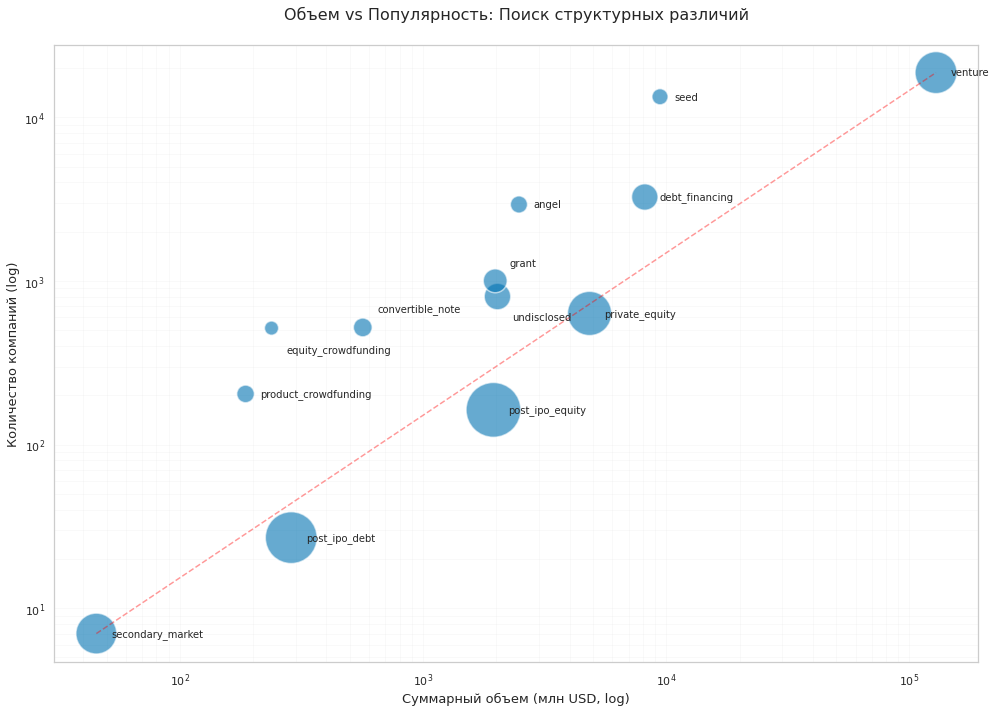

In [51]:
# Готовим данные (объемы, популярность и средний чек для размера пузырька)
scatter_df = pd.DataFrame({
    'Volume': volumes,
    'Popularity': popularity,
    'Avg_Check': volumes / popularity
}).sort_values(by='Volume', ascending=False)

plt.figure(figsize=(14, 10))

# Добавляем белую обводку (edgecolor) —  "разлепим" наложенные круги
sns.scatterplot(data=scatter_df, x='Volume', y='Popularity', 
                size='Avg_Check', sizes=(200, 3000), # Немного увеличим масштаб
                alpha=0.6, color='#0072B2', edgecolor='white', linewidth=1.5, legend=False)

# Линия тренда
plt.plot([scatter_df.Volume.min(), scatter_df.Volume.max()], 
         [scatter_df.Popularity.min(), scatter_df.Popularity.max()], 
         color='red', linestyle='--', alpha=0.4)

# Логарифмическая шкала
plt.xscale('log')
plt.yscale('log')

# Умные подписи без наслоения
for i in range(len(scatter_df)):
    label = scatter_df.index[i]
    x = scatter_df.Volume[i]
    y = scatter_df.Popularity[i]
    
    # Смещаем подписи для "тесных" зон
    if label in ['grant', 'convertible_note']:
        va, y_mult = 'bottom', 1.2  # Текст выше точки
    elif label in ['undisclosed', 'equity_crowdfunding']:
        va, y_mult = 'top', 0.8     # Текст ниже точки
    else:
        va, y_mult = 'center', 1.0  # По центру
        
    plt.text(x * 1.15, y * y_mult, label, fontsize=10, va=va, ha='left', fontweight='medium')

plt.title('Объем vs Популярность: Поиск структурных различий', fontsize=16, pad=25)
plt.xlabel('Суммарный объем (млн USD, log)', fontsize=13)
plt.ylabel('Количество компаний (log)', fontsize=13)
plt.grid(True, which="both", ls="-", alpha=0.1)

plt.tight_layout()
plt.show()

График наглядно подтверждает переход от количества (верхний левый сектор) к качеству и объему капитала (нижний правый сектор), где `Venture` выступает связующим звеном. 

- Выше пунктирной линии (`Seed`, `Angel`): Сегменты с низким средним чеком. Здесь высокая активность (много сделок), но малый объем капитала в расчете на одну компанию.
- Ниже пунктирной линии (`Private Equity`, `Post-IPO Debit`): Сегменты с высоким средним чеком. Сделок мало, но каждая из них требует крупных капиталовложений.
- `Venture`- единственный сегмент, сочетающий одновременно высокую частоту сделок и значительные объемы финансирования.

<a id='chapter5'></a>
## 5. Анализ динамики
<a id='chapter5.1'></a>
### 5.1 Динамика предоставления финансирования по годам

Переходим к изучению того, как менялся венчурный рынок во времени. Cопоставим интенсивность рынка (количество сделок) с "типичным чеком".

- Определим средний объём одного раунда для каждой компании, чтобы понимать «вес» единичного вложения.
- Сгруппируем данные по годам, рассчитав медианное значение чека (чтобы исключить влияние аномальных сделок) и общее количество раундов за каждый период.
- Построим совмещенный график, где столбцы покажут активность рынка, а линия — динамику типичного размера вложений.
- Сводная таблица: представим точные расчетные значения в табличном виде для детального сравнения показателей в ключевые периоды развития рынка.

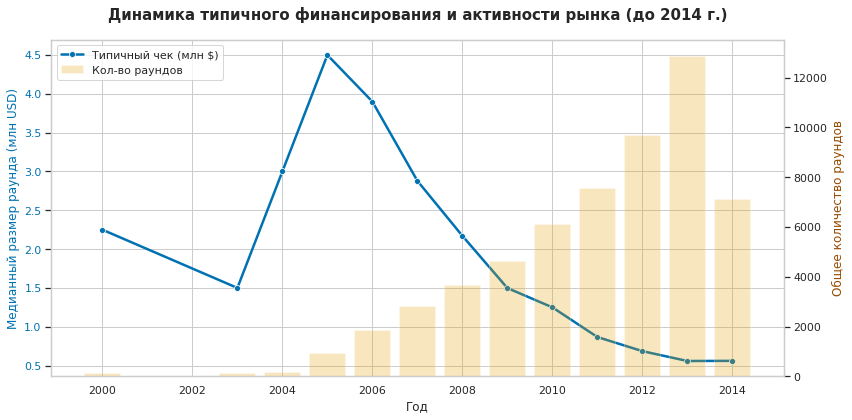

Статистика по годам:


,Типичный размер раунда (USD),Общее кол-во раундов
mid_funding_at,,
2014,"560,932","7,124"
2013,"559,000","12,880"
2012,"686,000","9,707"
2011,"867,685","7,578"
2010,"1,250,000","6,136"
2009,"1,498,475","4,617"
2008,"2,170,744","3,663"
2007,"2,879,167","2,842"
2006,"3,900,000","1,849"


In [52]:
df_dynamics = investments_final.copy()
df_dynamics = df_dynamics[df_dynamics['funding_rounds'] > 0]

# Расчет среднего чека на один раунд
df_dynamics['avg_round_funding'] = (
    df_dynamics['funding_total_usd'] / df_dynamics['funding_rounds']
)

# Группировка по годам
yearly_stats = df_dynamics.groupby(df_dynamics['mid_funding_at'].dt.year).agg(
    typical_sum=('avg_round_funding', 'median'),
    total_rounds=('funding_rounds', 'sum')
)

# Переименовываем столбцы для итоговой таблицы
yearly_stats_display = yearly_stats.rename(columns={
    'typical_sum': 'Типичный размер раунда (USD)',
    'total_rounds': 'Общее кол-во раундов'
}).sort_index(ascending=False)

# Настройка отображения чисел (убираем e+05, добавляем разделитель тысяч)
pd.options.display.float_format = '{:,.0f}'.format

# Визуализация 
sns.set_theme(style="whitegrid")
fig, ax1 = plt.subplots(figsize=(12, 6))

color_blue = "#0072B2"
color_orange = "#E69F00"

# Линия типичного чека (в млн USD для шкалы)
sns.lineplot(x=yearly_stats.index, y=yearly_stats['typical_sum'] / 1_000_000, 
             ax=ax1, color=color_blue, marker='o', linewidth=2.5, label='Типичный чек (млн $)')

ax1.set_title('Динамика типичного финансирования и активности рынка (до 2014 г.)', 
             fontsize=15, pad=20, fontweight='bold')
ax1.set_xlabel('Год', fontsize=12)
ax1.set_ylabel('Медианный размер раунда (млн USD)', fontsize=12, color=color_blue)
ax1.tick_params(axis='y', labelcolor=color_blue)

# Столбцы активности
ax2 = ax1.twinx()
ax2.bar(yearly_stats.index, yearly_stats['total_rounds'], 
        alpha=0.25, color=color_orange, label='Кол-во раундов')
ax2.set_ylabel('Общее количество раундов', fontsize=12, color='#964B00')
ax2.grid(False)

lines, labels = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines + lines2, labels + labels2, loc='upper left')

plt.tight_layout()
plt.show()

print("Статистика по годам:")
display(yearly_stats_display)

Анализ динамики финансирования показывает, что максимальный типичный размер инвестиционного раунда наблюдался в **2005** году и составил **4,5 млн USD**. При этом количество раундов в этот период было относительно небольшим — **948 сделок**.

В последующие годы на рынке сформировалась устойчивая тенденция: количество инвестиционных раундов быстро росло, тогда как медианный размер одного раунда постепенно снижался. **К 2013** году число раундов достигло **12 880**, а типичный размер инвестиций сократился до **559 тыс. USD**.

**В 2014** году зафиксировано **7 124 раунда**. Проверка подтвердила полноту данных за весь год, поэтому снижение относительно 2013 года интерпретируется как рыночная коррекция, а не технический сбой. При этом качественные показатели рынка остаются устойчивыми: медианный размер раунда практически не изменился и составил около **560 тыс. USD**.


    
    Таким образом, **с 2005 по 2013 год** наблюдается характерная динамика: инвестиционная активность значительно выросла, тогда как типичный размер раунда уменьшился примерно в 8 раз. Это свидетельствует о том, что рынок венчурного финансирования стал более массовым и доступным для большего числа стартапов.

<a id='chapter5.2'></a>
### 5.2 Динамика размера общего финансирования по массовым сегментам рынка для растущих в 2014 году сегментов
На предыдущих этапах сегменты рынка были классифицированы по количеству компаний на `mass`, `mid` и `niche`. В рамках этой задачи нас интересуют только массовые сегменты, поскольку именно они формируют основную динамику венчурного рынка.

Для анализа:

- построим сводную таблицу суммарного финансирования по годам и сегментам;

- отоберем только те массовые сегменты, где общий объём финансирования вырос в 2014 году относительно 2013 года;

- построим график динамики финансирования для этих сегментов.

In [53]:
df_segments = investments_final.copy()

# Оставляем только массовые сегменты
df_segments = df_segments[df_segments['market'].isin(
    [m for m, c in segment_map.items() if c == 'mass']
)]
# Создаём сводную таблицу финансирования
# Добавляем год
df_segments['year'] = df_segments['mid_funding_at'].dt.year

# Сводная таблица: сумма финансирования по годам и сегментам
funding_pivot = df_segments.pivot_table(
    values='funding_total_usd',
    index='year',
    columns='market',
    aggfunc='sum'
)
display("Сводная таблица суммарного финансирования:")
display(funding_pivot)

'Сводная таблица суммарного финансирования:'

market,advertising,analytics,apps,automotive,big data,biotechnology,clean technology,cloud computing,consulting,curated web,design,e-commerce,education,enterprise software,entertainment,fashion,finance,games,hardware + software,health and wellness,health care,hospitality,internet,manufacturing,marketplaces,medical,messaging,mobile,music,networking,news,nonprofits,photography,public relations,real estate,saas,search,security,semiconductors,social media,social network media,software,sports,startups,technology,travel,unknown_market,video,web hosting
year,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
2000,"14,470,000","14,822,803",NaN,NaN,NaN,NaN,NaN,"11,500,000","4,500,000","1,000,000",NaN,"32,879,052",NaN,"4,711,445","100,000",NaN,"15,000,000","21,728,774",NaN,"11,900,000","16,000,000",NaN,"10,000,000","56,659,310",NaN,"24,000,000",NaN,"10,000,000",NaN,NaN,NaN,"6,500,000",NaN,NaN,"2,500,000",NaN,"2,001,000","20,211,700",NaN,NaN,NaN,"31,732,640",NaN,NaN,NaN,"50,230","1,839,560",NaN,"95,343,090"
2003,"10,500,000","3,840,000",NaN,"4,530,000",NaN,"85,531,178","50,352,939",NaN,NaN,"2,550,000",NaN,NaN,"2,500,000","7,669,661",NaN,"9,800,000","25,320,000","11,348,830","12,200,000","3,414,041",NaN,NaN,NaN,"4,269,608",NaN,NaN,NaN,"8,010,058",NaN,NaN,"1,000,000",NaN,"7,100,000",NaN,"6,292,200",NaN,"5,000,000","13,650,000","28,000,000","5,000",NaN,"66,086,037",NaN,NaN,NaN,NaN,"4,155,202","5,000,000",NaN
2004,"6,000,000","3,000,000",NaN,NaN,NaN,"97,184,859","50,427,954",NaN,NaN,"27,050,000",NaN,"1,505,741","1,350,000","4,500,000",NaN,NaN,NaN,"38,150,000","14,775,000",NaN,"22,219,087",NaN,"10,500,000","3,000,000",NaN,NaN,"13,300,000","69,822,132",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"10,800,000","68,350,000","88,782,797","6,850,000",NaN,"140,823,795",NaN,NaN,"1,750,000","10,230,000","10,847,977","14,704,000","27,000,000"
2005,"127,196,022","79,014,044",NaN,"22,500,000",NaN,"480,063,583","19,420,000",NaN,"44,862,000","53,450,000","9,300,000","10,568,620","4,751,000","320,413,544","10,000,000",NaN,"48,235,001","86,626,921","280,865,552","30,210,000","111,091,410","1,020,480","1,775,000","61,770,000",NaN,"11,090,000","115,917,020","219,894,870","9,970,000",NaN,"9,590,000","17,051,520","7,000,000","79,695,875","250,000","5,240,000","11,800,000","333,759,701","586,220,751","14,780,000","5,200,000","993,076,581","1,882,200",NaN,"50,728,425","27,830,000","28,384,331","6,470,551","483,332,632"
2006,"299,299,458","139,701,311","1,310,600","12,660,000",NaN,"903,500,543","131,473,889","9,951,809","23,965,548","164,673,698","707,000","111,222,710","9,511,823","828,288,298","1,800,000","2,620,000","185,839,768","289,892,138","411,754,024","20,770,000","623,056,656","14,655,808","5,000","163,957,751",NaN,"20,250,000","145,133,772","347,275,817","56,466,885","26,889,850","37,116,568","12,880,000","6,686,406","38,600,000","2,080,000","4,791,121","37,821,719","237,943,300","1,227,940,797","60,169,880","5,245,100","1,646,868,624","7,000,000",NaN,"22,791,000","11,700,000","46,049,840","35,171,772","649,959,267"
2007,"556,704,331","98,829,000",NaN,"37,712,601","7,780,000","1,704,078,338","749,711,239","20,354,343","70,346,345","314,704,515","10,800,000","87,784,386","30,283,001","955,973,554","31,224,025","2,000,000","371,704,739","563,631,628","492,471,382","66,828,401","806,054,641","13,547,173","4,495,379","147,726,051","4,145,720","2,100,000","75,270,099","405,971,659","61,033,838","43,745,721","60,941,043","200,000","10,115,000","28,510,000","33,220,000","14,652,595","49,639,551","396,996,223","1,616,604,148","89,022,516","24,104,021","1,686,115,571","16,401,580",NaN,"180,190,209","13,950,000","35,532,468","85,150,644","361,121,449"
2008,"622,673,464","208,077,840","4,300,000","59,478,635","2,452,515","1,716,033,000","3,165,808,492","44,375,000","19,061,080","336,500,027","5,944,302","177,398,187","85,012,747","991,664,296","33,600,000","34,246,883","314,876,377","435,172,418","298,931,267","17,467,779","1,029,156,722","6,544,195","23,412,964","173,054,260","

In [54]:
# Выбираем сегменты, где финансирование выросло
growing_segments = funding_pivot.loc[2014] > funding_pivot.loc[2013]

growing_segments = growing_segments[growing_segments].index

display("Сегменты с ростом финансирования в 2014:")
display(list(growing_segments))

'Сегменты с ростом финансирования в 2014:'

['apps',
 'big data',
 'design',
 'internet',
 'manufacturing',
 'medical',
 'real estate',
 'saas',
 'startups',
 'technology',
 'unknown_market']

После построения сводной таблицы были отобраны массовые сегменты, в которых суммарный объём финансирования в 2014 году оказался выше, чем в 2013 году.

Полученный список отражает направления рынка, где инвестиционная активность продолжала расти.

Однако количество таких сегментов довольно велико, что может затруднять интерпретацию графика. Поэтому для наглядности рассмотрим несколько крупнейших сегментов по объёму финансирования в 2014 году, чтобы проследить динамику инвестиций в наиболее значимых направлениях рынка.

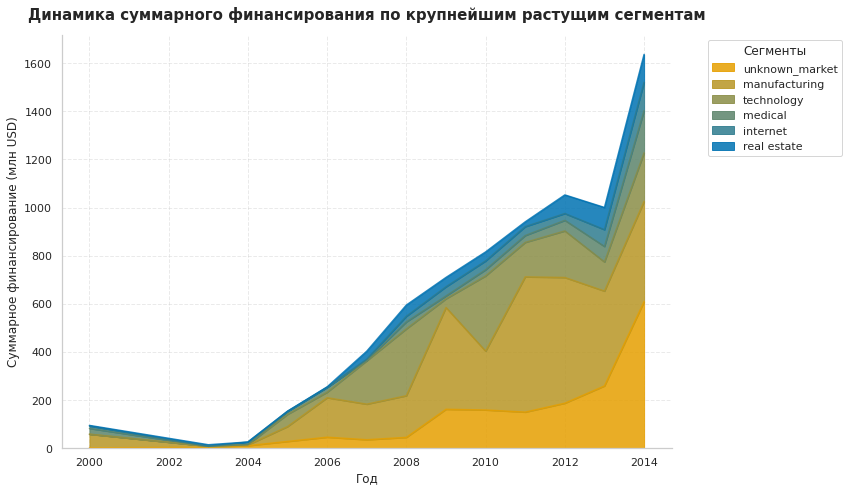

In [55]:
# Оставляем только сегменты с ростом
funding_growing = funding_pivot[growing_segments]

# Выбираем ТОП-6 сегментов по объему финансирования в 2014 году
top_segments = funding_growing.loc[2014].sort_values(ascending=False).head(6).index

# Таблица только с этими сегментами
funding_top = funding_growing[top_segments]

# Переведем значения в миллионы долларов
funding_top_mln = funding_top / 1_000_000

# Используем палитру проекта
# Нарезаем cmap на 6 мягких переходов
palette = [cmap(i / (len(funding_top_mln.columns) - 1)) for i in range(len(funding_top_mln.columns))]


# Построение stacked area графика
plt.figure(figsize=(12,7))

funding_top_mln.plot.area(
    ax=plt.gca(),
    color=palette,
    alpha=0.85
)

plt.title(
    "Динамика суммарного финансирования по крупнейшим растущим сегментам",
    fontsize=15,
    fontweight="bold",
    pad=15
)

plt.xlabel("Год")
plt.ylabel("Суммарное финансирование (млн USD)")

plt.grid(True, linestyle="--", alpha=0.4)

plt.legend(
    title="Сегменты",
    bbox_to_anchor=(1.05, 1),
    loc="upper left"
)

sns.despine()

plt.tight_layout()
plt.show()

На основе сводной таблицы были выделены сегменты, в которых **суммарный объём финансирования в 2014 году оказался выше, чем в 2013 году**. К таким сегментам относятся: `apps`, `big data`, `design`, `internet`, `manufacturing`, `medical`, `real estate`, `saas`, `startups`, `technology ` и `unknown_market`.

Для более наглядного анализа на графике были представлены **крупнейшие из этих сегментов по объёму финансирования**, что позволило проследить долгосрочную динамику инвестиций.

Анализ графика показывает следующие тенденции:

- Сегменты `technology` и `internet` демонстрируют наиболее устойчивый рост финансирования на протяжении нескольких лет, начиная примерно с 2008–2009 годов. Это указывает на высокий и стабильный интерес инвесторов к технологическим решениям и интернет-проектам.

- Сегмент `medical` также показывает заметный рост объёмов инвестиций, особенно после 2011 года, что может отражать активное развитие медицинских и биотехнологических стартапов.

- Сегмент `real estate` демонстрирует резкий рост в последние годы, особенно в 2013–2014 годах, что может быть связано с появлением новых цифровых платформ и сервисов в сфере недвижимости.

Другие сегменты, такие как `manufacturing` и `unknown_market`, также показывают увеличение финансирования, однако их динамика менее стабильна и выражена слабее.

В целом анализ показывает, что **наиболее быстрый и уверенный рост** финансирования наблюдается в сегментах `technology`, `internet` и `medical`, которые можно рассматривать как ключевые драйверы развития венчурного рынка в рассматриваемый период.

<a id='chapter5.3'></a>
### 5.3 Годовая динамика доли возвращённых средств по типам финансирования
В этом разделе оценим эффективность различных типов финансирования. 
Для каждого года рассчитаем долю возвращённых средств (ROI) — отношение суммы возвратов к объёму предоставленного финансирования.

Показатель позволит понять, какая часть инвестированных средств возвращается инвесторам со временем.

Чтобы избежать деления на ноль, при расчёте добавим к знаменателю небольшое число (1e-60). 
Также исключим аномальные значения — слишком большие показатели ROI, которые могут искажать анализ.

In [56]:
# Настройка отображения чисел в таблице
pd.set_option('display.float_format', '{:.3f}'.format)

# Считаем объемы вложений по годам и переводим в млн $
funding_mln = (
    investments_final.groupby(investments_final['mid_funding_at'].dt.year)[funding_types]
    .sum() / 1_000_000.0
)

# Считаем долю возврата (ROI)
roi_by_year = returns[funding_types] / (funding_mln + 1e-60)

# Очистка аномалий (значения > 10 заменяем на пропуски)
roi_by_year = roi_by_year.where(roi_by_year <= 10, None)

# Вывод таблицы
print("Итоговая таблица доли возвращённых средств (все типы финансирования):")
display(roi_by_year.T)

Итоговая таблица доли возвращённых средств (все типы финансирования):


,2000,2001,2002,2003,2004,2005,2006,2007,2008,2009,2010,2011,2012,2013,2014
seed,0.996,None,None,0.505,0.548,0.675,0.925,0.366,0.297,0.563,0.527,0.272,0.195,0.148,0.279
venture,0.169,None,None,0.628,0.837,0.547,0.344,0.297,0.191,0.170,0.199,0.257,0.316,0.354,0.784
equity_crowdfunding,0.000,None,None,0.000,0.000,0.000,0.204,None,None,0.088,0.053,0.097,0.029,0.025,0.007
undisclosed,0.697,None,None,0.914,0.528,1.072,0.759,0.505,0.342,0.376,0.248,0.229,0.158,0.271,0.516
convertible_note,0.000,None,None,None,None,None,0.166,0.228,0.060,0.055,0.068,0.050,0.045,0.049,0.067
debt_financing,0.619,None,None,1.038,0.440,0.345,0.804,0.602,0.927,0.388,0.445,0.501,0.505,0.486,1.242
angel,0.267,None,None,0.606,0.834,0.510,0.675,0.818,0.412,0.616,0.640,0.438,0.501,0.542,1.153
grant,0.000,None,None,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000
private_equity,0.000,None,None,None,None,0.480,0.935,0.579,0.680,0.789,0.646,0.731,0.928,0.616,1.107
post_ipo_equity,0.271,None,None,None,None,0.732,None,2.030,2.341,2.096,1.353,0.667,0.806,0.561,0.267


Таблица показывает долю возвращённых средств для каждого типа финансирования по годам. 
Значение показателя интерпретируется следующим образом:

- значение **1.0** означает полную окупаемость вложений;
- значение **меньше 1** — возврат только части инвестиций;
- значение **больше 1** — возврат превышает объём вложенных средств.

Для более наглядного анализа распределения показателя по годам и типам финансирования построим тепловую карту.

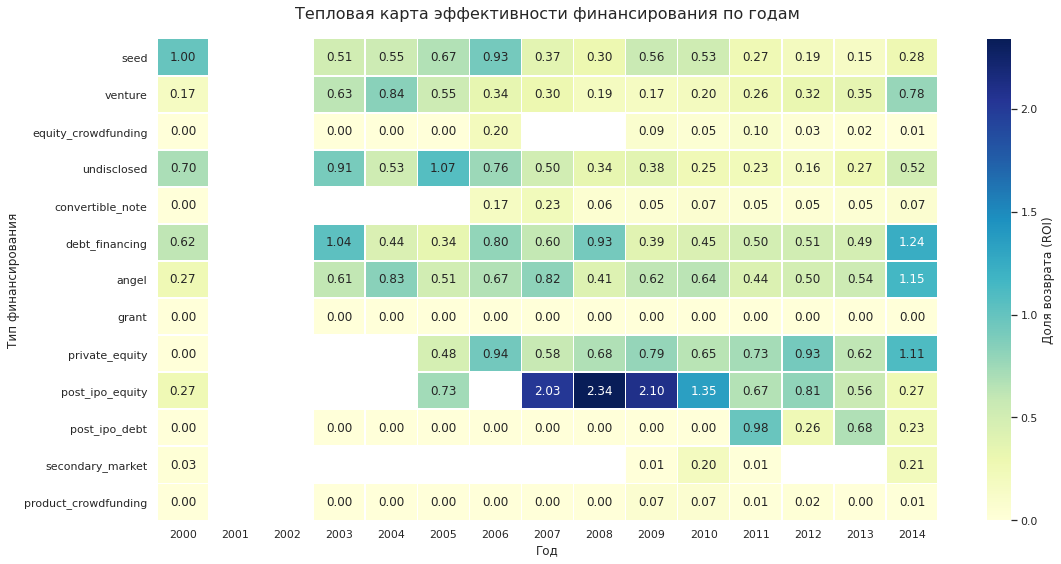

In [57]:
# Подготовка данных: транспонируем, чтобы типы были строками, а годы — столбцами
plot_data = roi_by_year.T.astype(float)

# Настройка стиля и палитры
plt.figure(figsize=(16, 8))
# 'YlGnBu' —  палитра (желтый-зеленый-синий)
# annot=True добавит числа внутрь ячеек для наглядности
sns.heatmap(
    plot_data, 
    annot=True, 
    fmt=".2f", 
    cmap="YlGnBu", 
    linewidths=.5, 
    cbar_kws={'label': 'Доля возврата (ROI)'},
    mask=plot_data.isnull() # Красиво скроем NaN (они останутся белыми)
)

# Оформление
plt.title('Тепловая карта эффективности финансирования по годам', fontsize=16, pad=20)
plt.ylabel('Тип финансирования', fontsize=12)
plt.xlabel('Год', fontsize=12)

plt.tight_layout()
plt.show()


Из карты видно, что многие типы финансирования большую часть времени имеют значения **ниже 1**, то есть инвестиции не всегда полностью окупаются в рассматриваемый период.

Например, для **venture-финансирования** значения ROI чаще находятся в диапазоне примерно **0.17–0.84**, что говорит о возврате только части вложенных средств. Похожая ситуация наблюдается и для **seed-инвестиций**, где показатель колеблется примерно от **0.15 до 0.93**, что отражает высокий риск инвестиций на ранних стадиях развития компаний.

Для **angel-финансирования** значения ROI в большинстве лет находятся примерно в диапазоне **0.4–0.8**, а в 2014 году достигают значения около **1.15**, что означает возврат средств, превышающий объём вложений.

Наиболее высокие значения ROI наблюдаются у **debt_financing** и **private_equity**. Например, для **debt_financing** показатель достигает около **1.24** в 2014 году, а для **private_equity** — около **1.11**, что говорит о высокой эффективности этих видов финансирования в отдельные годы.

В целом тепловая карта показывает, что более зрелые формы инвестирования чаще демонстрируют более высокую долю возврата средств, тогда как инвестиции ранних стадий характеризуются большей нестабильностью показателя.

Построим график для пяти основных типов финансирования:
- venture
- debt_financing
- private_equity
- seed
- angel

Это позволит сравнить, как менялась эффективность различных видов инвестиций во времени.

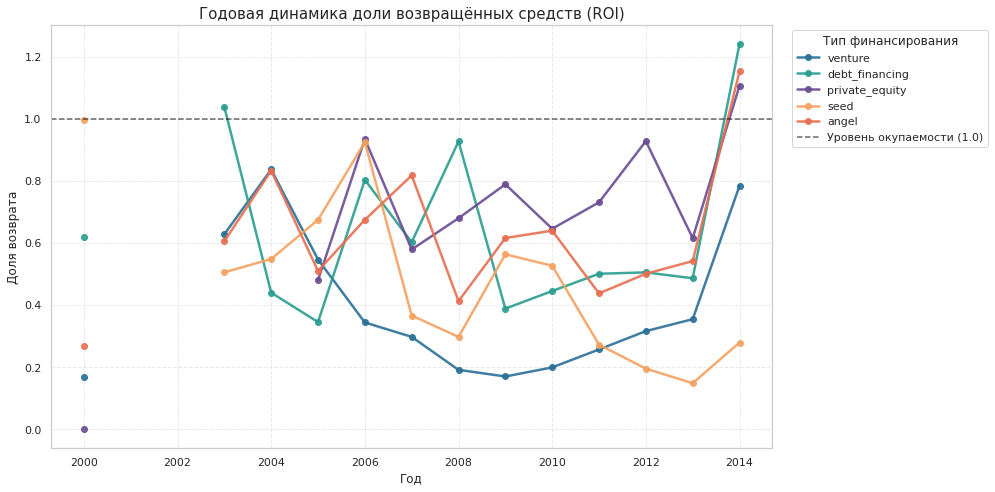

In [58]:
# Готовим список типов финансирования
target_types = ['venture', 'debt_financing', 'private_equity', 'seed', 'angel']


# Задаём фиксированные цвета для каждого типа финансирования
colors = {
    'seed': '#f4a261',
    'angel': '#e76f51',
    'venture': '#2a6f97',
    'private_equity': '#6a4c93',
    'debt_financing': '#2a9d8f'
}


# Готовим полотно
plt.figure(figsize=(14,7))


# Строим линии динамики ROI для каждого типа финансирования
for col in target_types:
    
    plt.plot(
        roi_by_year.index,      
        roi_by_year[col],       
        marker='o',             
        linewidth=2.5,         
        markersize=6,           
        color=colors[col],      
        label=col,           
        alpha=0.9               
    )


# Добавляем горизонтальную линию уровня окупаемости

plt.axhline(
    y=1,
    color='black',
    linestyle='--',
    alpha=0.6,
    label='Уровень окупаемости (1.0)'
)


# Заголовок графика
plt.title("Годовая динамика доли возвращённых средств (ROI)", fontsize=15)


# Подписи осей
plt.xlabel("Год")
plt.ylabel("Доля возврата")


# Добавляем сетку для удобства чтения графика
plt.grid(True, linestyle="--", alpha=0.4)


# Отображаем легенду справа от графика
plt.legend(title="Тип финансирования", bbox_to_anchor=(1.02,1))
plt.tight_layout()
plt.show()

Линейный график позволяет проследить, как менялась доля возвращённых средств (ROI) для различных типов финансирования во времени.

1. **Debt financing** демонстрирует одну из наиболее устойчивых динамик возврата средств. В течение большинства лет показатель находится в диапазоне примерно **0.4–0.9**, а к **2014 году достигает около 1.24**, что означает возврат средств, превышающий объём вложений.

2. **Private equity** также показывает относительно стабильный рост эффективности инвестиций. Начиная с середины периода значения постепенно увеличиваются и к **2014 году достигают примерно 1.1**, что свидетельствует о высокой окупаемости таких инвестиций.

3. **Angel-инвестиции** характеризуются более волатильной динамикой: показатель ROI заметно колеблется в разные годы, однако в **2014 году также превышает уровень окупаемости (около 1.15)**.

4. **Venture-финансирование** демонстрирует более низкие значения ROI по сравнению с другими типами инвестиций. В большинстве лет показатель находится в диапазоне **0.17–0.5**, лишь к концу периода увеличиваясь примерно до **0.78**.

5. **Seed-инвестиции** показывают наиболее нестабильную динамику. После относительно высоких значений в середине периода показатель постепенно снижается и остаётся значительно ниже уровня окупаемости.

Таким образом, наиболее устойчивый рост доли возвращённых средств наблюдается для **debt_financing** и **private_equity**, тогда как инвестиции ранних стадий (**seed** и частично **venture**) характеризуются более высокой волатильностью и меньшей окупаемостью.

<a id='chapter6'></a>
## 6. Итоговый вывод и рекомендации по инвестиционной стратегии 2015

**1. Краткое резюме выполненной работы**

**Предобработка данных**
- Удалены дубликаты и пустые строки
- Пропуски в ключевых показателях обработаны
- Типы данных приведены к корректным форматам
- Исключены выбросы аномально высоких инвестиций

**Инжиниринг признаков**
- Компании классифицированы по срокам финансирования
- Сегменты рынка:
  - `mass` — массовые сегменты рынка (рынки с большим количеством компаний)
  - `mid` — средние сегменты (рынки со средним количеством компаний)
  - `niche` — нишевые сегменты (рынки с небольшим количеством компаний)

- Типы инвестиций: `Venture`, `Seed`/`Angel`, `Debt Financing`, `Private Equity`

**Анализ структуры рынка**
- 59% компаний ограничиваются единичным финансированием
- Долгосрочные проекты (>1 года) аккумулируют 62% всех инвестиций

**Анализ сегментов**
- Массовые сегменты концентрируют наибольшую инвестиционную активность
- Нишевые и средние сегменты многочисленны, но менее капиталоёмки

**Анализ типов финансирования**
- `Venture` — основной инструмент по объёму инвестиций и количеству сделок; доля возвращённых средств ниже, чем у `Debt Financing` и `Private Equity` (0.17–0.78)
- `Seed`/`Angel` — много сделок, малые суммы; подходит для ранних стадий
- `Debt Financing` и `Private Equity` — небольшое количество сделок, крупные суммы, стабильная прибыль

**Динамика рынка (2005–2013)**
- Резкий рост количества инвестиционных раундов
- Медианный размер раунда снизился с ~4,5 млн до ~0,56 млн USD
- Свидетельствует о массовизации венчурного рынка

**2. Основные выводы**

**Длительность финансирования ↔ концентрация капитала**
- Долгосрочные проекты привлекают большую часть капитала
- Короткие циклы характерны для множества мелких стартапов с небольшими инвестициями

**Фрагментация рынка**
- Большинство сегментов — `niche`, малое количество компаний
- `Mass` — меньшинство компаний, но концентрируют капитал и инвесторов

**Отрасли с устойчивым ростом и высоким инвестиционным потенциалом (2013–2014)**
- `Technology`
- `Internet`
- `Medical`

**Эффективные типы финансирования для инвестиций в 2015 году**
- Основной: `Venture` — сочетание объёма и частоты сделок; доля возврата ниже, поэтому это ставка на рост, а не на быструю окупаемость
- Дополнительно: `Debt Financing` и `Private Equity` — для зрелых компаний: наибольшая доля возвращённых средств (около 1.24 и 1.11 в 2014 году)

**3. Рекомендации для инвестора на 2015 год**

**Выбор отрасли для инвестирования**
- Основной фокус: `Technology`, `Internet`, `Medical` — устойчивый рост финансирования, крупные и массовые сегменты, высокая активность
- Второстепенный фокус: перспективные niche направления — для диверсификации и поиска уникальных возможностей

**Тип финансирования**
- Основной инструмент: `Venture` (долгосрочные проекты)
- Дополнительно: `Debt Financing` для зрелых компаний
- `Seed`/`Angel` — ограниченно, для тестирования идей и ранней поддержки

**Стратегия по срокам и объёмам**
- Приоритет долгосрочным проектам (>1 года)
- Сосредоточение на массовых сегментах (`mass`)
- Использовать медианные показатели инвестиций для оценки «типичного» чека и избегания искажений от аномальных сделок

**4. Согласованность выводов**
- Промежуточные выводы согласуются: долгосрочные проекты концентрируют капитал, `Venture` — эффективный инструмент, массовые сегменты растут устойчиво
- Возможные сомнения: прогноз на 2015 следует корректировать с учётом роста рынка и тенденций 2013–2014

**Итоговая рекомендация**

Для выхода на рынок венчурного финансирования в 2015 году инвестору целесообразно инвестировать в крупные компании из массовых сегментов `Technology`, `Internet` и `Medical` через `Venture`-финансирование, дополняя стратегию `Debt Financing` для зрелых проектов.

Диверсификация по нишевым сегментам (`niche`) возможна, но с учетом более высокого риска и меньшего объема инвестиций.